# M12.5.1 — Sesgo condicionado y sensibilidad al ruido

Este notebook consume únicamente CSV/JSON del piloto; no abre strain ni checkpoints, ni genera señales o predicciones. Las nueve fuentes son condiciones físicas fijas, no 576 fuentes independientes. La varianza entre ruidos no es incertidumbre posterior, incertidumbre epistémica ni riesgo Bayes irreducible. Los cuatro modelos son endpoints congelados de una sola semilla de entrenamiento.

**Contrato:** masas `(20,15), (40,30), (70,50)` en masas solares del detector, cruzadas con spins longitudinales iguales `−0.6,0,+0.6`; SNR óptima sin ruido `10,15,20,24.5`; 16 ruidos por condición; H1/L1/V1; etiquetas `[chirp_mass,total_mass,chi_eff]`. No selección con val/cal/test ni eventos reales.

**Procedencia:** entorno, PSD, extrínsecos y semilla de colocación de la fila train 0 del G1 reparado. La colocación `random_contained` depende de la duración de cada fuente; permanece fija entre SNR y ruidos de esa fuente. No se impone un GPS idéntico entre fuentes de distinta duración. Cada distancia se calibra usando exclusivamente la señal sin ruido y la PSD G1.

**Puerta obligatoria:** filas train prefijadas 0, 1 y 5830. Comprueba el generador histórico y el adaptador del piloto. `allclose(atol=rtol=1e-5)`, error L2 relativo ≤1e-6 y metadatos compatibles; GPS con tolerancia absoluta de 1 μs. No equivale a una afirmación universal de igualdad bit a bit. Un fallo no permite generar el piloto. No se leen filas held-out; el CSV se recorre solo hasta la fila train 5830 y su hash histórico completo se registra sin recalcularlo.


## Ejecución CLI (usuario; no ejecutar este notebook en la VM)

Desde el repositorio, con `CBC_PE_DATA_ROOT` apuntando a los artefactos externos. Cada destino debe ser nuevo; no hay overwrite ni resume de salidas parciales. Los comandos con generación/inferencia requieren `--run`.

```bash
python scripts/m12/reproduce_m12_5_1_g1.py --run --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/gate_v1"
python scripts/m12/run_m12_5_1_pilot.py generate --run --gate "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/gate_v1/gate.json" --preserve-raw --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/pilot_v1"
python scripts/m12/run_m12_5_1_pilot.py infer --run --pilot "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/pilot_v1" --device cuda --batch-size 16 --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/inference_v1"
python scripts/m12/analyze_m12_5_1.py --inference "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/inference_v1" --output-dir "$CBC_PE_DATA_ROOT/results/M11_final_G1_500k/M12_5_1/analysis_v1"
```

Generación/puerta requieren las versiones físicas históricas del HDF5 (NumPy, SciPy, PyCBC y LALSuite), además de código físico coincidente por hash. Pandas, h5py, torch, Python y plataforma se registran; no se exige torch 2.11.0 para inferencia. Inferencia separada usa APIs PyTorch 1.9.1, `no_grad`, `eval`, cargas CPU y batches acotados; puede ejecutarse en `cbc_torch` después de transferir el piloto completo. La compatibilidad binaria real de checkpoints con esa VM debe comprobarse allí; un error produce recibo incompleto. No se instala nada automáticamente.

La puerta se vincula a rutas, tamaño/mtime, código, versiones y hashes de los intervalos PSD; ejecútela y genere en el mismo entorno. Puede transferir después el piloto a otro entorno para inferencia; se validan sus hashes de contenido. No genere desde un gate antiguo tras editar código o sustituir entradas.

Artefactos: `gate.json`; `observations.h5`, `conditions.csv`, `observations.csv`, `generation.json`; `predictions.csv`, `inference.json`; opcionalmente métricas CSV y `analysis.json`. El HDF5 guarda X, verdad física, IDs, semillas y PSD numéricas; con `--preserve-raw` añade strain señal+ruido y señal limpia en contexto (float64). X ocupa 108 MiB sin comprimir; raw + señal limpia añaden unos 276 MiB: total aproximado 385 MiB más metadatos, antes de LZF. Sin raw, ~109 MiB. No es un dataset de entrenamiento. No se modifican G1 ni checkpoints.

Para análisis local basta copiar `predictions.csv` e `inference.json`; los CSV auxiliares del piloto permiten inspeccionar los parámetros completos. No hace falta transferir HDF5 ni checkpoints al notebook.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/paths.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
from scripts.m12 import m12_5_common as contracts
from scripts.m12.analyze_m12_5_1 import analyze

DATA_ROOT = Path("/data/vserrano/cbc_pe_data")  # CBC_PE_DATA_ROOT; existing project convention.
INFERENCE_DIR = DATA_ROOT / "results/M11_final_G1_500k/M12_5_1/inference_v1"
receipt = contracts.read_json(INFERENCE_DIR / "inference.json")
summary, paired = analyze(INFERENCE_DIR / "predictions.csv", receipt, bootstrap=2000)
display(pd.DataFrame([dict(model=k, sha256=v["sha256"], epoch=v["epoch"],
                           y_mean=v["y_mean"], y_std=v["y_std"])
                      for k,v in receipt["checkpoints"].items()]))
print("Device:", receipt["device"], "torch:", receipt["torch_version"])


,model,sha256,epoch,y_mean,y_std
0,M11,3670f0dbe985cf4b3405ee47b970eedd56f573d0cd5741...,75,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
1,M12.1,2b573cc67b3bcee54881f174381706286db6a41ef20c52...,51,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
2,M12.2,8d33c89ebc670a0570aac7f88da012ac6975900f2ebcac...,83,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."
3,M12.3-S1,45826a25ac854a8b85e2b65b186e810468e6646fe4b671...,29,"[37.46354675292969, 94.98597717285156, -0.0002...","[16.508060455322266, 34.70329284667969, 0.4403..."


Device: cuda torch: 1.9.1+cu111


## Estimandos y precisión Monte Carlo

Para R=16, sesgo = media de predicciones − verdad fija; varianza muestral con ddof=1. Se exporta la identidad exacta finita

$$\widehat{MSE}=\widehat b^2+\frac{R-1}{R}s^2.$$

Los IC son percentiles bootstrap puntuales al 95%, 2000 remuestreos de realizaciones dentro de cada condición. Todos los modelos usan los mismos índices bootstrap; las condiciones se mantienen separadas. Con 16 realizaciones los IC de varianza y colas son exploratorios. No hay corrección por comparaciones múltiples ni incertidumbre entre semillas de entrenamiento. Masas: M⊙; chi_eff: adimensional; varianza y MSE: unidades al cuadrado.


In [2]:
display(summary[["source_id", "target_snr", "model", "label", "truth", "mean_prediction",
                 "bias", "sample_variance", "conditional_mse", "bias_squared",
                 "finite_R_variance_component", "decomposition_residual"]])
print("Máximo residuo de identidad:", summary.decomposition_residual.abs().max())


,source_id,target_snr,model,label,truth,mean_prediction,bias,sample_variance,conditional_mse,bias_squared,finite_R_variance_component,decomposition_residual
0,M1251_SRC_00,10.0,M11,chi_eff,-0.600000,-0.049426,0.550574,0.078420,0.376650,0.303132,0.073518,6.938894e-17
1,M1251_SRC_00,10.0,M12.1,chi_eff,-0.600000,-0.084250,0.515750,0.099412,0.359197,0.265998,0.093199,0.000000e+00
2,M1251_SRC_00,10.0,M12.2,chi_eff,-0.600000,-0.025928,0.574072,0.076856,0.401612,0.329559,0.072053,2.775558e-17
3,M1251_SRC_00,10.0,M12.3-S1,chi_eff,-0.600000,0.027629,0.627629,0.077981,0.467025,0.393918,0.073107,1.110223e-16
4,M1251_SRC_00,10.0,M11,chirp_mass,15.047320,20.735323,5.688003,11.761391,43.379687,32.353383,11.026304,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...
427,M1251_SRC_08,24.5,M12.3-S1,chirp_mass,51.357583,48.367206,-2.990377,6.526635,15.061078,8.942357,6.118720,-9.769963e-15
428,M1251_SRC_08,24.5,M11,total_mass,120.000000,114.652186,-5.347814,14.726080,42.404816,28.599116,13.805700,4.973799e-14
429,M1251_SRC_08,24.5,M12.1,total_mass,120.000000,116.169616,-3.830384,15.364573,29.076131,14.671844,14.404287,2.664535e-14
430,M1251_SRC_08,24.5,M12.2,total_mass,120.000000,115.886383,-4.113617,22.466508,37.984193,16.921842,21.062351,7.105427e-15


Máximo residuo de identidad: 2.8421709430404007e-13


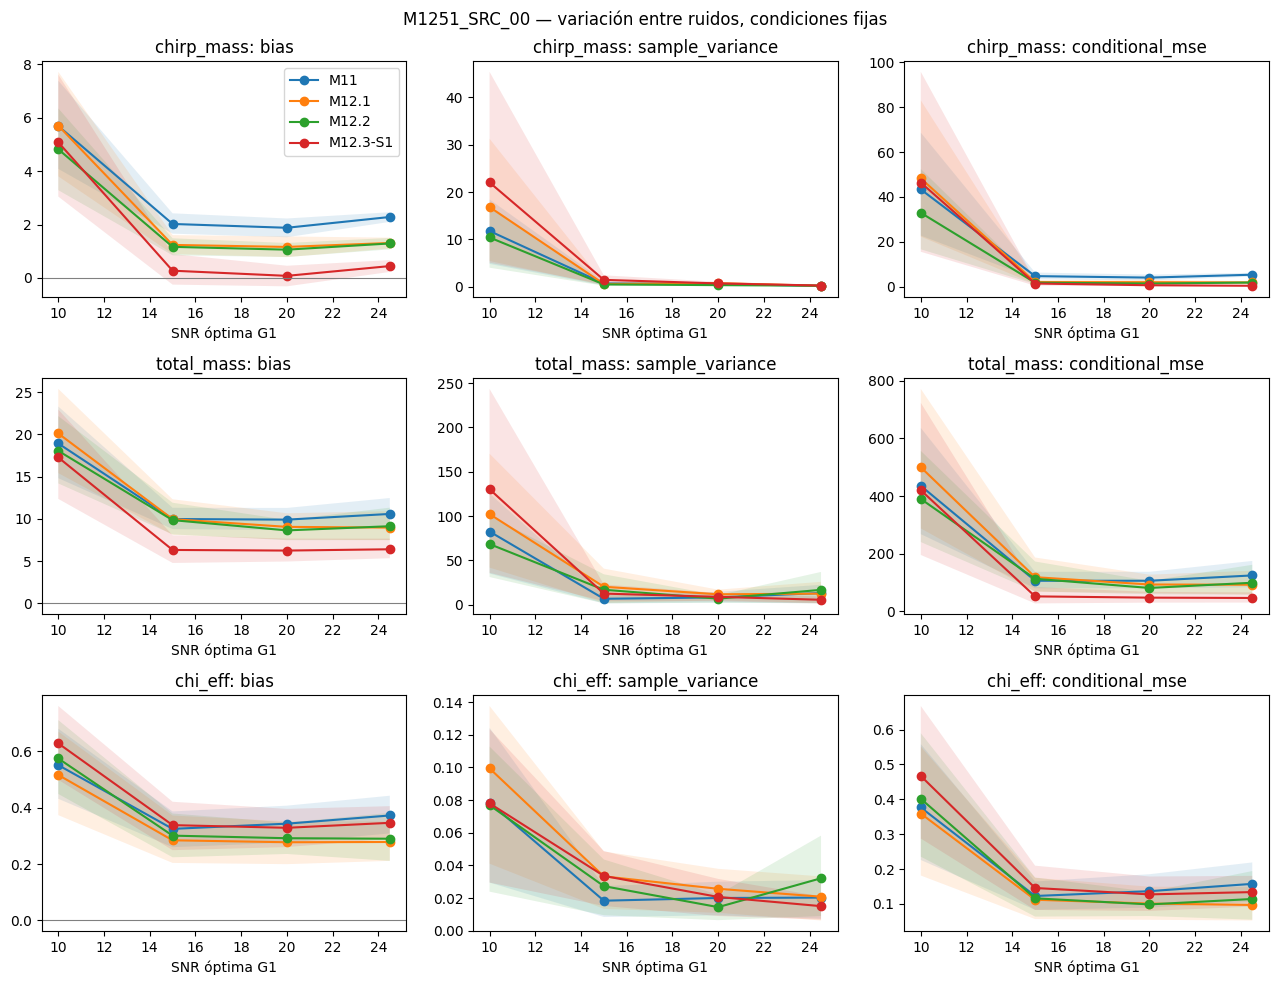

In [3]:
SOURCE_TO_VIEW = "M1251_SRC_00"  # Visualización, no selección de variantes.
metrics = ["bias", "sample_variance", "conditional_mse"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for j, label in enumerate(contracts.LABELS):
    for k, metric in enumerate(metrics):
        ax = axes[j, k]
        for model in contracts.MODEL_TAGS:
            frame = summary[(summary.source_id == SOURCE_TO_VIEW) & (summary.label == label)
                            & (summary.model == model)].sort_values("target_snr")
            ax.plot(frame.target_snr, frame[metric], marker="o", label=model)
            ax.fill_between(frame.target_snr.to_numpy(), frame[metric+"_ci_low"].to_numpy(),
                            frame[metric+"_ci_high"].to_numpy(), alpha=.12)
        if metric == "bias":
            ax.axhline(0, color="gray", linewidth=.8)
        ax.set_title(f"{label}: {metric}")
        ax.set_xlabel("SNR óptima G1")
axes[0,0].legend()
fig.suptitle(SOURCE_TO_VIEW + " — variación entre ruidos, condiciones fijas")
fig.tight_layout()
plt.show()


## Contracción y extremos de la cuadrícula

La figura siguiente compara medias por fuente con sus verdades, a una SNR predefinida. Los extremos corresponden solo a esta cuadrícula: no son Q10/Q90 de G1 ni una estimación de rendimiento poblacional. Las masas repetidas con spins distintos conservan fuentes distintas. Separar sesgo persistente y dispersión al aumentar SNR; no atribuir un plateau al límite de información sin referencia probabilística compatible.


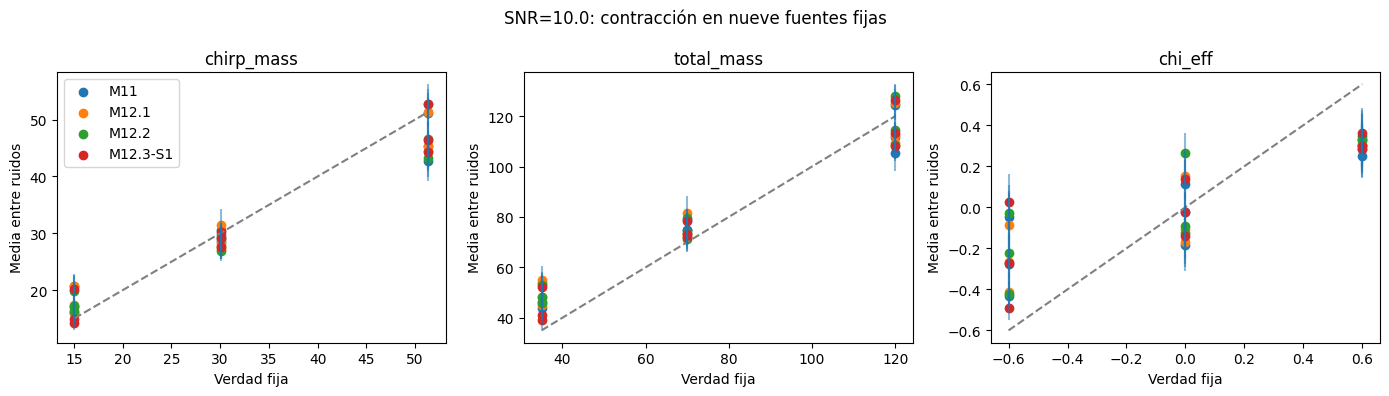

,source_id,target_snr,label,model_a,model_b,sign,delta_bias,delta_bias_ci_low,delta_bias_ci_high,delta_conditional_mse,delta_conditional_mse_ci_low,delta_conditional_mse_ci_high
0,M1251_SRC_00,10.0,chi_eff,M11,M12.1,a_minus_b,0.034824,-0.077823,0.139824,0.017453,-0.128540,0.148852
1,M1251_SRC_00,10.0,chi_eff,M11,M12.2,a_minus_b,-0.023498,-0.130451,0.074225,-0.024962,-0.187830,0.110237
2,M1251_SRC_00,10.0,chi_eff,M11,M12.3-S1,a_minus_b,-0.077055,-0.177015,0.022228,-0.090375,-0.229174,0.040833
3,M1251_SRC_00,10.0,chi_eff,M12.1,M12.2,a_minus_b,-0.058322,-0.136982,0.018611,-0.042415,-0.130563,0.061799
4,M1251_SRC_00,10.0,chi_eff,M12.1,M12.3-S1,a_minus_b,-0.111879,-0.205769,-0.010229,-0.107828,-0.256014,0.048072
...,...,...,...,...,...,...,...,...,...,...,...,...
643,M1251_SRC_08,24.5,total_mass,M11,M12.2,a_minus_b,-1.234198,-2.294914,-0.306122,4.420623,-4.586190,13.926664
644,M1251_SRC_08,24.5,total_mass,M11,M12.3-S1,a_minus_b,-1.787448,-2.927163,-0.730181,15.047698,1.844058,29.586882
645,M1251_SRC_08,24.5,total_mass,M12.1,M12.2,a_minus_b,0.283232,-0.556524,1.115500,-8.908062,-19.078491,-0.110772
646,M1251_SRC_08,24.5,total_mass,M12.1,M12.3-S1,a_minus_b,-0.270018,-1.214680,0.619495,1.719012,-8.135725,11.887590


In [4]:
SNR_TO_VIEW = 10.0
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, label in zip(axes, contracts.LABELS):
    frame = summary[(summary.label == label) & (summary.target_snr == SNR_TO_VIEW)]
    lo, hi = frame.truth.min(), frame.truth.max()
    ax.plot([lo,hi], [lo,hi], color="gray", linestyle="--")
    for model in contracts.MODEL_TAGS:
        part = frame[frame.model == model]
        ax.scatter(part.truth, part.mean_prediction, label=model)
        ax.vlines(part.truth, part.mean_prediction_ci_low, part.mean_prediction_ci_high, alpha=.5)
    ax.set_title(label); ax.set_xlabel("Verdad fija"); ax.set_ylabel("Media entre ruidos")
axes[0].legend()
fig.suptitle(f"SNR={SNR_TO_VIEW}: contracción en nueve fuentes fijas")
fig.tight_layout()
plt.show()
display(paired[["source_id", "target_snr", "label", "model_a", "model_b", "sign",
                "delta_bias", "delta_bias_ci_low", "delta_bias_ci_high",
                "delta_conditional_mse", "delta_conditional_mse_ci_low", "delta_conditional_mse_ci_high"]])


## Registro de interpretación (rellenar solo tras ejecución autorizada)

- Procedencia y puerta: [hashes, versiones, igualdad numérica y discrepancias].
- Sesgos condicionados y dependencia de SNR: [por etiqueta/fuente; sin agrupar fuentes].
- Sensibilidad al ruido: [varianza, IC y limitación R=16].
- Contrastes emparejados: [signo a−b, sesgo y MSE por separado].
- Limitaciones: no posterior, no riesgo Bayes irreducible, no incertidumbre epistémica ni reproducibilidad entre semillas. El entorno/PSD único limita generalización. Ninguna mejora científica se establece mediante la mera aprobación de tests o puerta.
- No lanzar otra generación, entrenamiento o estudio completo desde este notebook. El estudio de 12 800 entradas no está implementado.


## Análisis exhaustivo añadido — nueve fuentes, cuatro SNR y cuatro checkpoints

Las celdas anteriores, incluidas sus salidas ejecutadas, se conservan como registro histórico. Esta extensión vuelve a validar **inference_v1** y trabaja exclusivamente con CSV/JSON; no ejecuta modelos, lee HDF5 ni genera señales. Las celdas nuevas no tienen resultados precalculados: las conclusiones numéricas deben leerse de las tablas al ejecutarlas localmente.

Entradas adicionales: `pilot_v1/generation.json`, `conditions.csv` y `observations.csv`. Se comprueban sus hashes, el vínculo generación–inferencia y la alineación por observación. No se necesita el HDF5 del piloto. La pertenencia a nueve fuentes y sus parámetros se obtiene del manifiesto efectivo, no de ejemplos seleccionados a posteriori. Todas las rutas usan `pathlib.Path` y la resolución de datos del proyecto.

In [5]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

ANALYSIS_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/paths.py").is_file())
if str(ANALYSIS_ROOT) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_ROOT))
from src.paths import resolve_data_root
from scripts.m12 import m12_5_common as contracts
from scripts.m12.analyze_m12_5_1 import analyze

# Environment takes precedence; retain the existing notebook's Path as fallback.
ANALYSIS_DATA_ROOT = Path(resolve_data_root(config_data_root=globals().get("DATA_ROOT")))
STUDY_DIR = ANALYSIS_DATA_ROOT / "results" / contracts.DATASET / "M12_5_1"
EXHAUSTIVE_INFERENCE_DIR = STUDY_DIR / "inference_v1"
PILOT_METADATA_DIR = STUDY_DIR / "pilot_v1"
ex_receipt = contracts.read_json(EXHAUSTIVE_INFERENCE_DIR / "inference.json")
gen_receipt = contracts.read_json(PILOT_METADATA_DIR / "generation.json")
contracts.require(gen_receipt.get("complete") is True, "Incomplete generation provenance")
contracts.require(contracts.digest(PILOT_METADATA_DIR / "generation.json") ==
                  ex_receipt["generation_sha256"], "Generation/inference mismatch")
for name in ("conditions.csv", "observations.csv"):
    contracts.require(contracts.digest(PILOT_METADATA_DIR / name) ==
                      gen_receipt["artifacts"][name]["sha256"], f"Changed metadata: {name}")
BOOTSTRAP_REPLICATES = 2000
ex_summary, ex_paired = analyze(EXHAUSTIVE_INFERENCE_DIR / "predictions.csv",
                               ex_receipt, bootstrap=BOOTSTRAP_REPLICATES)
ex_predictions = pd.read_csv(EXHAUSTIVE_INFERENCE_DIR / "predictions.csv")
ex_conditions = pd.read_csv(PILOT_METADATA_DIR / "conditions.csv")
ex_observations = pd.read_csv(PILOT_METADATA_DIR / "observations.csv")
MODEL_ORDER = list(contracts.MODEL_TAGS)
LABEL_ORDER = list(contracts.LABELS)
SNR_ORDER = list(contracts.SNRS)
SOURCE_ORDER = [f"M1251_SRC_{i:02d}" for i in range(9)]
contracts.require(len(ex_conditions) == 36 and ex_conditions.condition_id.is_unique,
                  "Expected 36 unique conditions")
contracts.require(len(ex_observations) == 576 and ex_observations.observation_id.is_unique,
                  "Expected 576 observations")
contracts.require(set(ex_conditions.source_id) == set(SOURCE_ORDER), "Source grid changed")
contracts.require(ex_observations.groupby("condition_id").size().eq(16).all(), "R != 16")
seeds = ex_observations[[f"seed_{d}" for d in contracts.DETECTORS]].to_numpy().ravel()
contracts.require(len(np.unique(seeds)) == 1728, "Repeated detector seed in pilot")
check = ex_predictions.merge(ex_observations, on="observation_id", suffixes=("", "_manifest"),
                             validate="many_to_one", how="left")
for key in ("condition_id", "realization_id", "source_id", "tensor_sha256"):
    contracts.require(check[key].eq(check[key+"_manifest"]).all(), f"Alignment: {key}")
for name in MODEL_ORDER:
    contracts.require(ex_receipt["checkpoints"][name]["sha256"] == contracts.MODEL_HASHES[name],
                      f"Unexpected checkpoint: {name}")
train_means = np.asarray(ex_receipt["checkpoints"]["M11"]["y_mean"], dtype=float)
train_stds = np.asarray(ex_receipt["checkpoints"]["M11"]["y_std"], dtype=float)
for name in MODEL_ORDER:
    for key, expected in (("y_mean", train_means), ("y_std", train_stds)):
        contracts.require(np.array_equal(ex_receipt["checkpoints"][name][key], expected),
                          f"Different frozen scaler: {name}")
display(pd.DataFrame({"label": LABEL_ORDER, "G1_train_mean": train_means,
                      "G1_train_std": train_stds}))

,label,G1_train_mean,G1_train_std
0,chirp_mass,37.463547,16.508060
1,total_mass,94.985977,34.703293
2,chi_eff,-0.000219,0.440338


### Tabla completa y significado de los intervalos

Se reutilizan `analyze` y `contracts.moments`: las definiciones de MSE, sesgo y varianza no cambian. La tabla contiene **432 filas** (9×4×4×3), con verdad física, parámetros individuales y unidades. La desviación estándar y RMSE son raíces de la varianza y MSE correspondientes. Sus IC se obtienen mediante transformación monótona de los IC existentes. El IC de sesgo absoluto es la imagen del intervalo de sesgo firmado: incluye cero si aquel cruza cero, evitando un intervalo percentil ingenuo de valor absoluto que excluya cero artificialmente.

Son intervalos **puntuales, exploratorios, de incertidumbre Monte Carlo entre ruidos a condición fija**, con R=16. No garantizan cobertura fiable en colas, no son intervalos posteriores, no incluyen variación entre semillas de entrenamiento ni incertidumbre de población. No hay corrección por multiplicidad.

La fracción `bias_squared / conditional_mse` es una fracción algebraica del MSE empírico finito. El cuadrado del sesgo estimado no es un estimador insesgado del sesgo poblacional al cuadrado. No se asigna un IC a esa fracción ni se interpreta como proporción de error irreducible. Si MSE=0, la fracción queda indefinida.

In [6]:
intrinsics = ["mass_1", "mass_2", "spin_1z", "spin_2z"]
true_columns = {label: "true_"+label for label in LABEL_ORDER}
condition_table = ex_conditions[["condition_id", "source_id", *intrinsics,
                                 *LABEL_ORDER, "target_network_snr", "final_network_snr",
                                 "final_distance", "actual_geocentric_time", "block_id"]].rename(
                                     columns=true_columns)
exhaustive = ex_summary.merge(condition_table, on=["condition_id", "source_id"],
                              validate="many_to_one", how="left")
contracts.require(len(exhaustive) == 432 and not exhaustive[intrinsics].isna().any().any(),
                  "Incomplete exhaustive table")
contracts.require(exhaustive.target_snr.eq(exhaustive.target_network_snr).all(), "SNR mismatch")
for label in LABEL_ORDER:
    part = exhaustive[exhaustive.label.eq(label)]
    contracts.require(np.allclose(part.truth, part["true_"+label], atol=1e-12, rtol=1e-12),
                      "True labels disagree with physical manifest")
for sid, group in condition_table.groupby("source_id"):
    contracts.require(group[intrinsics + list(true_columns.values())].nunique().eq(1).all(),
                      f"Physical source changed across SNR: {sid}")
    contracts.require(group.actual_geocentric_time.nunique() == 1, "Placement changes with SNR")
exhaustive["absolute_bias"] = exhaustive.bias.abs()
lo, hi = exhaustive.bias_ci_low, exhaustive.bias_ci_high
exhaustive["absolute_bias_ci_low"] = np.where((lo <= 0) & (hi >= 0), 0, np.minimum(abs(lo), abs(hi)))
exhaustive["absolute_bias_ci_high"] = np.maximum(abs(lo), abs(hi))
for new, old in (("noise_std", "sample_variance"), ("conditional_rmse", "conditional_mse")):
    exhaustive[new] = np.sqrt(exhaustive[old])
    for suffix in ("_ci_low", "_ci_high"):
        exhaustive[new+suffix] = np.sqrt(exhaustive[old+suffix])
exhaustive["bias_mse_fraction"] = exhaustive.bias_squared.div(
    exhaustive.conditional_mse.where(exhaustive.conditional_mse > 0))
exhaustive["noise_variance_mse_fraction"] = exhaustive.finite_R_variance_component.div(
    exhaustive.conditional_mse.where(exhaustive.conditional_mse > 0))
exhaustive["variance_unit"] = np.where(exhaustive.label.eq("chi_eff"), "dimensionless^2", "Msun^2")
contracts.require(np.allclose(exhaustive.conditional_mse,
                  exhaustive.bias_squared + (exhaustive.R-1)/exhaustive.R*exhaustive.sample_variance,
                  rtol=1e-10, atol=1e-12), "Finite-R decomposition violated")
exhaustive = exhaustive.sort_values(["source_id", "target_snr", "model", "label"]).reset_index(drop=True)
with pd.option_context("display.max_rows", 432, "display.max_columns", None):
    display(exhaustive[["source_id", *intrinsics, *true_columns.values(), "target_snr", "model", "label",
                       "unit", "R", "mean_prediction", "mean_prediction_ci_low", "mean_prediction_ci_high",
                       "bias", "bias_ci_low", "bias_ci_high", "absolute_bias", "absolute_bias_ci_low",
                       "absolute_bias_ci_high", "sample_variance", "sample_variance_ci_low",
                       "sample_variance_ci_high", "noise_std", "noise_std_ci_low", "noise_std_ci_high",
                       "conditional_mse", "conditional_mse_ci_low", "conditional_mse_ci_high",
                       "conditional_rmse", "conditional_rmse_ci_low", "conditional_rmse_ci_high",
                       "bias_mse_fraction"]])

,source_id,mass_1,mass_2,spin_1z,spin_2z,true_chirp_mass,true_total_mass,true_chi_eff,target_snr,model,label,unit,R,mean_prediction,mean_prediction_ci_low,mean_prediction_ci_high,bias,bias_ci_low,bias_ci_high,absolute_bias,absolute_bias_ci_low,absolute_bias_ci_high,sample_variance,sample_variance_ci_low,sample_variance_ci_high,noise_std,noise_std_ci_low,noise_std_ci_high,conditional_mse,conditional_mse_ci_low,conditional_mse_ci_high,conditional_rmse,conditional_rmse_ci_low,conditional_rmse_ci_high,bias_mse_fraction
0,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M11,chi_eff,dimensionless,16,-0.049426,-0.168806,0.079485,0.550574,0.431194,0.679485,0.550574,0.431194,0.679485,0.078420,0.029493,0.124291,0.280035,0.171734,0.352549,0.376650,0.225944,0.558225,0.613718,0.475336,0.747144,0.804810
1,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M11,chirp_mass,Msun_detector_frame,16,20.735323,19.130202,22.429227,5.688003,4.082882,7.381907,5.688003,4.082882,7.381907,11.761391,4.813322,18.430523,3.429488,2.193928,4.293079,43.379687,22.798400,68.671892,6.586326,4.774767,8.286851,0.745819
2,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M11,total_mass,Msun_detector_frame,16,53.924992,49.820775,58.295891,18.924992,14.820775,23.295891,18.924992,14.820775,23.295891,82.576335,35.171930,125.349061,9.087152,5.930593,11.195939,435.570652,267.920073,636.720680,20.870329,16.368264,25.233325,0.822267
3,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.1,chi_eff,dimensionless,16,-0.084250,-0.226655,0.069228,0.515750,0.373345,0.669228,0.515750,0.373345,0.669228,0.099412,0.041080,0.137598,0.315297,0.202683,0.370942,0.359197,0.181428,0.551380,0.599331,0.425944,0.742550,0.740535
4,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.1,chirp_mass,Msun_detector_frame,16,20.748871,18.851097,22.761851,5.701552,3.803777,7.714532,5.701552,3.803777,7.714532,16.824138,5.435622,31.274150,4.101724,2.331442,5.592330,48.280319,22.343338,83.083781,6.948404,4.726874,9.115030,0.673311
5,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.1,total_mass,Msun_detector_frame,16,55.106892,50.420301,60.380564,20.106892,15.420301,25.380564,20.106892,15.420301,25.380564,102.180580,41.895470,170.316253,10.108441,6.472671,13.050527,500.081420,287.862144,772.018382,22.362500,16.966501,27.785219,0.808443
6,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.2,chi_eff,dimensionless,16,-0.025928,-0.151570,0.109988,0.574072,0.448430,0.709988,0.574072,0.448430,0.709988,0.076856,0.023935,0.112748,0.277230,0.154710,0.335780,0.401612,0.235550,0.589622,0.633729,0.485335,0.767869,0.820591
7,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.2,chirp_mass,Msun_detector_frame,16,19.864185,18.332558,21.392098,4.816865,3.285239,6.344779,4.816865,3.285239,6.344779,10.396854,4.003990,16.708137,3.224415,2.000997,4.087559,32.949239,16.683095,52.454753,5.740143,4.084495,7.242565,0.704180
8,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.2,total_mass,Msun_detector_frame,16,53.052490,49.195906,57.159416,18.052490,14.195906,22.159416,18.052490,14.195906,22.159416,68.423353,31.266969,100.057323,8.271841,5.591687,10.002866,390.039274,240.469442,556.899555,19.749412,15.507077,23.598719,0.835537
9,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,10.0,M12.3-S1,chi_eff,dimensionless,16,0.027629,-0.101463,0.160156,0.627629,0.498537,0.760156,0.627629,0.498537,0.760156,0.077981,0.029510,0.123431,0.279251,0.171784,0.351327,0.467025,0.287538,0.667782,0.683393,0.536226,0.817179,0.843462


### Comparación SNR 24,5 − 10 y emparejamiento

Los modelos comparten realización **dentro** de cada condición; los ruidos de SNR 10 y 24,5 son distintos y sus semillas son únicas. Para el contraste entre SNR se remuestrea cada extremo independientemente, manteniendo índices comunes entre checkpoints dentro de cada extremo. No se emparejan artificialmente las realizaciones de SNR diferentes por tener el mismo número ordinal.

Se reutiliza el esquema RNG de `analyze` para construir distribuciones bootstrap de media, sesgo, varianza y MSE. La tabla de 108 filas incluye ambos extremos, cambios con signo alto−bajo, sesgo residual a SNR 24,5 e IC puntuales. Para el cambio de sesgo absoluto se resta la imagen de los intervalos marginales de sesgo; es una envolvente conservadora respecto de esos intervalos, **sin garantía nominal conjunta del 95%**. Evita afirmar precisión regular cerca de sesgo cero con solo 16 repeticiones. La etiqueta `high_bias_ci_excludes_zero` es descriptiva, no una prueba múltiple ni demostración de un sesgo asintótico a SNR infinita.

In [7]:
# Bounded scalar bootstrap: 16 realizations × 4 models, one condition/label at a time.
bootstrap_cache = {}
for (cid, label), group in ex_predictions.groupby(["condition_id", "label"], sort=True):
    pmat = group.pivot(index="realization_id", columns="model", values="prediction").reindex(
        index=range(16), columns=MODEL_ORDER).to_numpy()
    truth = float(group.truth.iloc[0])
    j = LABEL_ORDER.index(label)
    rng = np.random.default_rng(np.random.SeedSequence([125002, int(cid), j]))
    draws = rng.integers(0, 16, size=(BOOTSTRAP_REPLICATES, 16))
    samples = pmat[draws]
    boot_mean = samples.mean(axis=1)
    bootstrap_cache[(int(cid), label)] = {
        "bias": boot_mean-truth, "sample_variance": samples.var(axis=1, ddof=1),
        "conditional_rmse": np.sqrt(((samples-truth)**2).mean(axis=1))}
    for k, model in enumerate(MODEL_ORDER):
        measured = contracts.moments(pmat[:, k], truth)
        old = exhaustive[(exhaustive.condition_id == cid) & (exhaustive.label == label)
                         & (exhaustive.model == model)].iloc[0]
        contracts.require(all(np.isclose(old[key], value, rtol=1e-10, atol=1e-12)
                              for key, value in measured.items()), "Metric definition drift")

endpoint_rows = []
for (sid, model, label), frame in exhaustive.groupby(["source_id", "model", "label"], sort=True):
    low = frame[frame.target_snr.eq(10.)].iloc[0]
    high = frame[frame.target_snr.eq(24.5)].iloc[0]
    k = MODEL_ORDER.index(model)
    row = {key: low[key] for key in ["source_id", *intrinsics, *true_columns.values(), "model", "label", "unit", "R"]}
    row.update(snr_low=10., snr_high=24.5, delta_convention="24.5_minus_10")
    for metric in ("bias", "absolute_bias", "sample_variance", "noise_std", "conditional_rmse",
                   "conditional_mse", "bias_mse_fraction"):
        row[metric+"_snr10"] = low[metric]
        row[metric+"_snr24p5"] = high[metric]
        row["delta_"+metric] = high[metric]-low[metric]
    for metric in ("bias", "sample_variance", "conditional_rmse"):
        delta = (bootstrap_cache[(int(high.condition_id), label)][metric][:, k] -
                 bootstrap_cache[(int(low.condition_id), label)][metric][:, k])
        bounds = np.quantile(delta, [.025, .975])
        row["delta_"+metric+"_ci_low"], row["delta_"+metric+"_ci_high"] = bounds
    row["delta_absolute_bias_envelope_low"] = high.absolute_bias_ci_low - low.absolute_bias_ci_high
    row["delta_absolute_bias_envelope_high"] = high.absolute_bias_ci_high - low.absolute_bias_ci_low
    row.update(persistent_bias_at_24p5=high.bias, persistent_absolute_bias_at_24p5=high.absolute_bias,
               high_bias_ci_low=high.bias_ci_low, high_bias_ci_high=high.bias_ci_high,
               high_bias_ci_excludes_zero=bool(high.bias_ci_low > 0 or high.bias_ci_high < 0))
    endpoint_rows.append(row)
endpoints = pd.DataFrame(endpoint_rows)
contracts.require(len(endpoints) == 108, "Expected all 108 source/model/label contrasts")
with pd.option_context("display.max_rows", 108, "display.max_columns", None):
    display(endpoints)

# Existing paired MSE/bias/variance contrasts, plus paired RMSE contrasts.
paired_full = ex_paired.copy()
for index, row in paired_full.iterrows():
    a, b = MODEL_ORDER.index(row.model_a), MODEL_ORDER.index(row.model_b)
    boot = bootstrap_cache[(int(row.condition_id), row.label)]["conditional_rmse"]
    part = exhaustive[(exhaustive.condition_id == row.condition_id) & (exhaustive.label == row.label)].set_index("model")
    paired_full.loc[index, "delta_conditional_rmse"] = part.loc[row.model_a, "conditional_rmse"] - part.loc[row.model_b, "conditional_rmse"]
    bounds = np.quantile(boot[:, a]-boot[:, b], [.025, .975])
    paired_full.loc[index, ["delta_conditional_rmse_ci_low", "delta_conditional_rmse_ci_high"]] = bounds
paired_full = paired_full.merge(condition_table, on=["condition_id", "source_id"], validate="many_to_one")
contracts.require(len(paired_full) == 648, "Expected every condition, label and checkpoint pair")

,source_id,mass_1,mass_2,spin_1z,spin_2z,true_chirp_mass,true_total_mass,true_chi_eff,model,label,unit,R,snr_low,snr_high,delta_convention,bias_snr10,bias_snr24p5,delta_bias,absolute_bias_snr10,absolute_bias_snr24p5,delta_absolute_bias,sample_variance_snr10,sample_variance_snr24p5,delta_sample_variance,noise_std_snr10,noise_std_snr24p5,delta_noise_std,conditional_rmse_snr10,conditional_rmse_snr24p5,delta_conditional_rmse,conditional_mse_snr10,conditional_mse_snr24p5,delta_conditional_mse,bias_mse_fraction_snr10,bias_mse_fraction_snr24p5,delta_bias_mse_fraction,delta_bias_ci_low,delta_bias_ci_high,delta_sample_variance_ci_low,delta_sample_variance_ci_high,delta_conditional_rmse_ci_low,delta_conditional_rmse_ci_high,delta_absolute_bias_envelope_low,delta_absolute_bias_envelope_high,persistent_bias_at_24p5,persistent_absolute_bias_at_24p5,high_bias_ci_low,high_bias_ci_high,high_bias_ci_excludes_zero
0,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M11,chi_eff,dimensionless,16,10.0,24.5,24.5_minus_10,0.550574,0.372133,-0.178441,0.550574,0.372133,-0.178441,0.078420,0.020291,-0.058129,0.280035,0.142447,-0.137588,0.613718,0.396870,-0.216848,0.376650,0.157506,-0.219144,0.804810,0.879225,0.074415,-0.323917,-0.039529,-0.106973,-0.009095,-0.373013,-0.059499,-0.370964,0.010965,0.372133,0.372133,0.308522,0.442159,True
1,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M11,chirp_mass,Msun_detector_frame,16,10.0,24.5,24.5_minus_10,5.688003,2.281852,-3.406151,5.688003,2.281852,-3.406151,11.761391,0.148458,-11.612933,3.429488,0.385302,-3.044187,6.586326,2.312148,-4.274178,43.379687,5.346028,-38.033660,0.745819,0.973966,0.228147,-5.071409,-1.799548,-18.274363,-4.708956,-5.975380,-2.500073,-5.283688,-1.622649,2.281852,2.281852,2.098219,2.460234,True
2,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M11,total_mass,Msun_detector_frame,16,10.0,24.5,24.5_minus_10,18.924992,10.586838,-8.338155,18.924992,10.586838,-8.338155,82.576335,13.297025,-69.279310,9.087152,3.646509,-5.440644,20.870329,11.160067,-9.710262,435.570652,124.547096,-311.023556,0.822267,0.899910,0.077643,-12.955730,-3.895614,-112.546889,-21.111315,-14.448589,-4.762473,-14.290310,-2.350960,10.586838,10.586838,9.005581,12.469815,True
3,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M12.1,chi_eff,dimensionless,16,10.0,24.5,24.5_minus_10,0.515750,0.278210,-0.237540,0.515750,0.278210,-0.237540,0.099412,0.020846,-0.078566,0.315297,0.144381,-0.170916,0.599331,0.311358,-0.287972,0.359197,0.096944,-0.262253,0.740535,0.798409,0.057874,-0.407947,-0.075993,-0.119478,-0.018489,-0.455143,-0.099170,-0.457870,-0.022313,0.278210,0.278210,0.211358,0.351032,True
4,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M12.1,chirp_mass,Msun_detector_frame,16,10.0,24.5,24.5_minus_10,5.701552,1.309141,-4.392411,5.701552,1.309141,-4.392411,16.824138,0.188366,-16.635772,4.101724,0.434012,-3.667712,6.948404,1.374934,-5.573470,48.280319,1.890443,-46.389876,0.673311,0.906586,0.233275,-6.454318,-2.499425,-31.112899,-5.237462,-7.757129,-3.339432,-6.611593,-2.295146,1.309141,1.309141,1.102939,1.508632,True
5,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M12.1,total_mass,Msun_detector_frame,16,10.0,24.5,24.5_minus_10,20.106892,8.972041,-11.134852,20.106892,8.972041,-11.134852,102.180580,12.537091,-89.643489,10.108441,3.540776,-6.567666,22.362500,9.604740,-12.757760,500.081420,92.251039,-407.830380,0.808443,0.872592,0.064149,-16.699835,-6.110878,-158.670084,-25.760559,-18.667760,-6.984747,-17.893649,-4.508050,8.972041,8.972041,7.486914,10.912251,True
6,M1251_SRC_00,20.0,15.0,-0.6,-0.6,15.047320,35.0,-0.6,M12.2,chi_eff,dimensionless,16,10.0,24.5,24.5_minus_10,0.574072,0.289764,-0.284308,0.574072,0.289764,-0.284308,0.076856,0.032133,-0.044724,0.277230,0.179256,-0.097974,0.633729,0.337769,-0.295960,0.401612,0.114088,-0.287524,0.820591,0.735954,-0.084637,-0.442858,-0.132323,-0.090438,0.010117,-0.469835,-0.115678,-0.498687,-0.067026,0.289764,0.289764,0.211301,0.381404,True
7,M1251_SRC_00,20.0,15

### Figuras exhaustivas

Cada figura contiene nueve paneles, ordenados por masas (filas) y spins (columnas). El título de cada panel identifica la fuente y las tres verdades físicas; cada curva representa un checkpoint. Se muestran **todos los puntos SNR**, no solo casos ilustrativos. Las escalas verticales son comunes dentro de cada figura para facilitar comparación; las unidades de varianza y MSE están al cuadrado. Las bandas son puntuales, no simultáneas. Se cierran las figuras después de mostrarlas para limitar memoria.

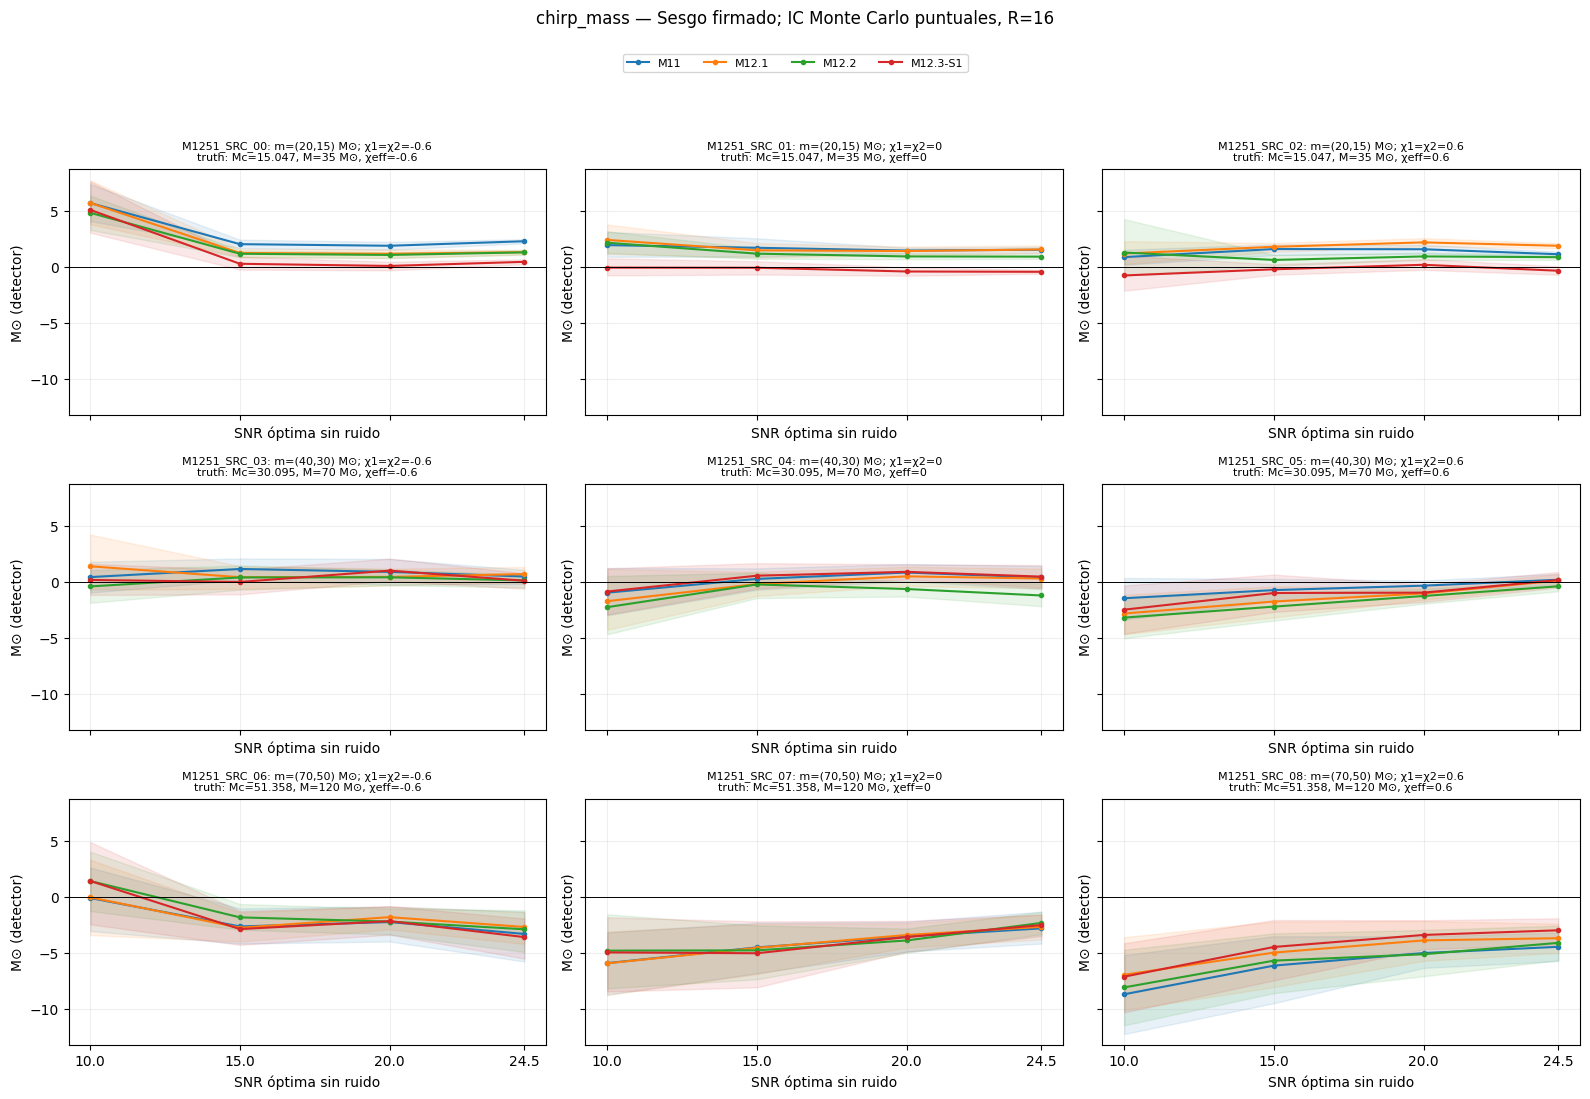

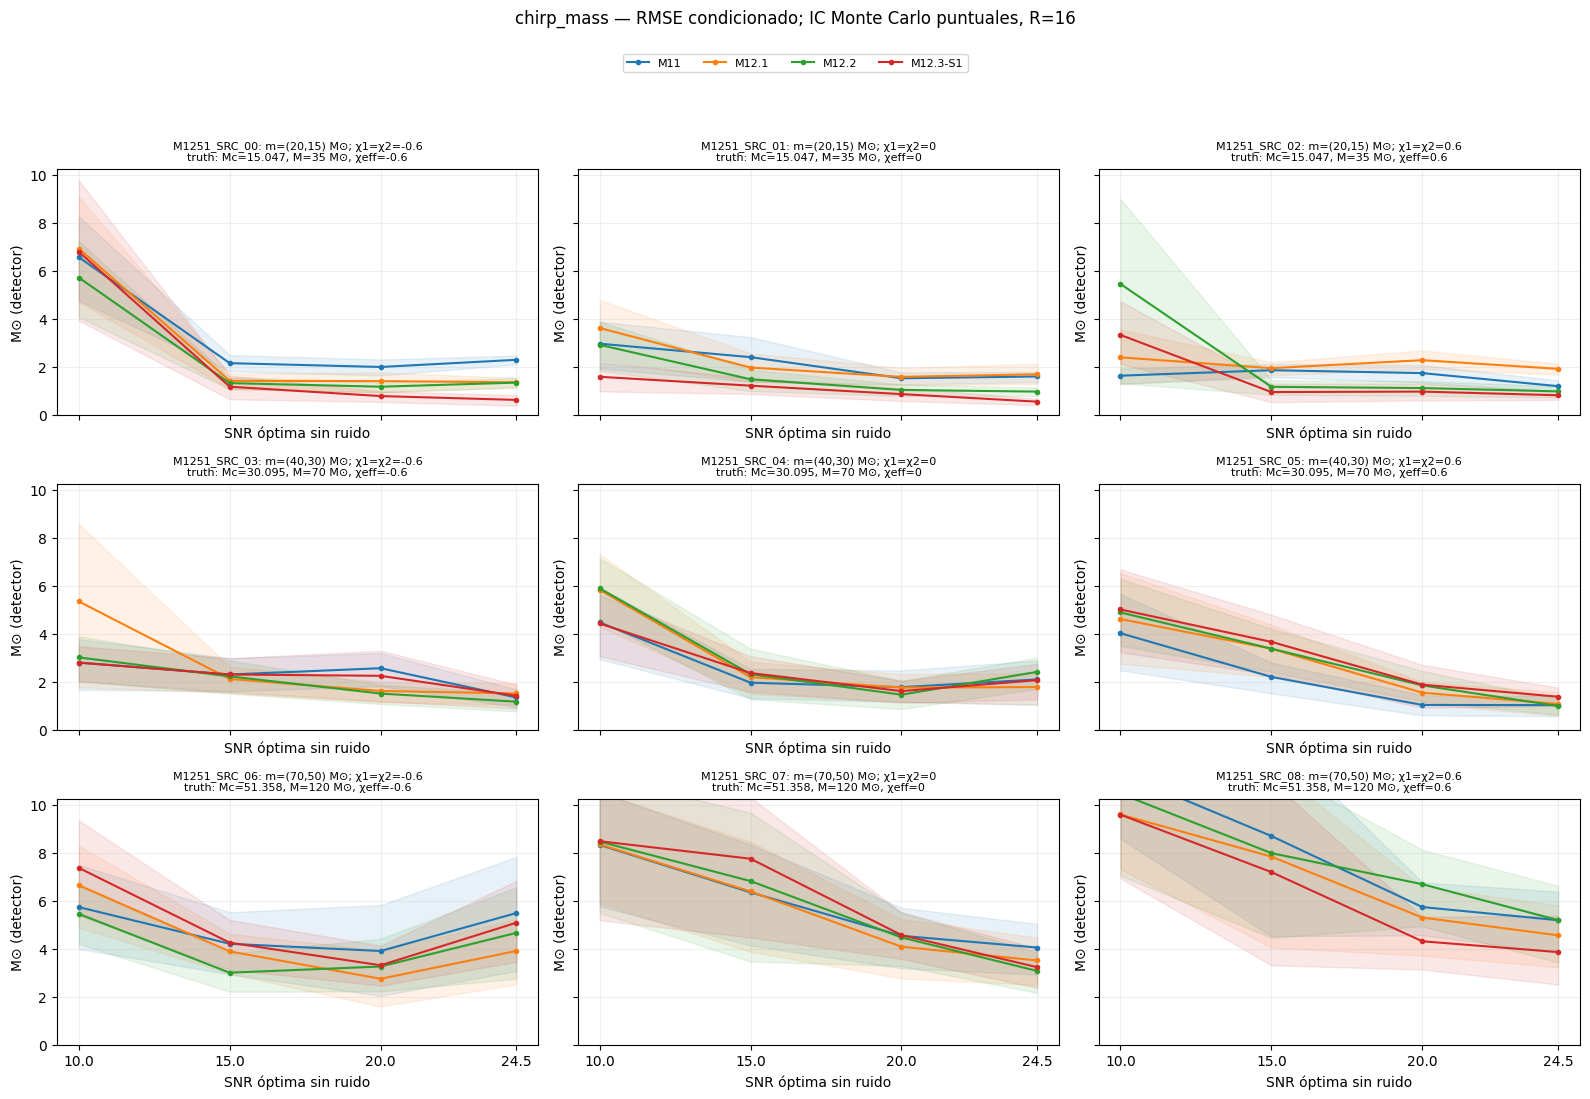

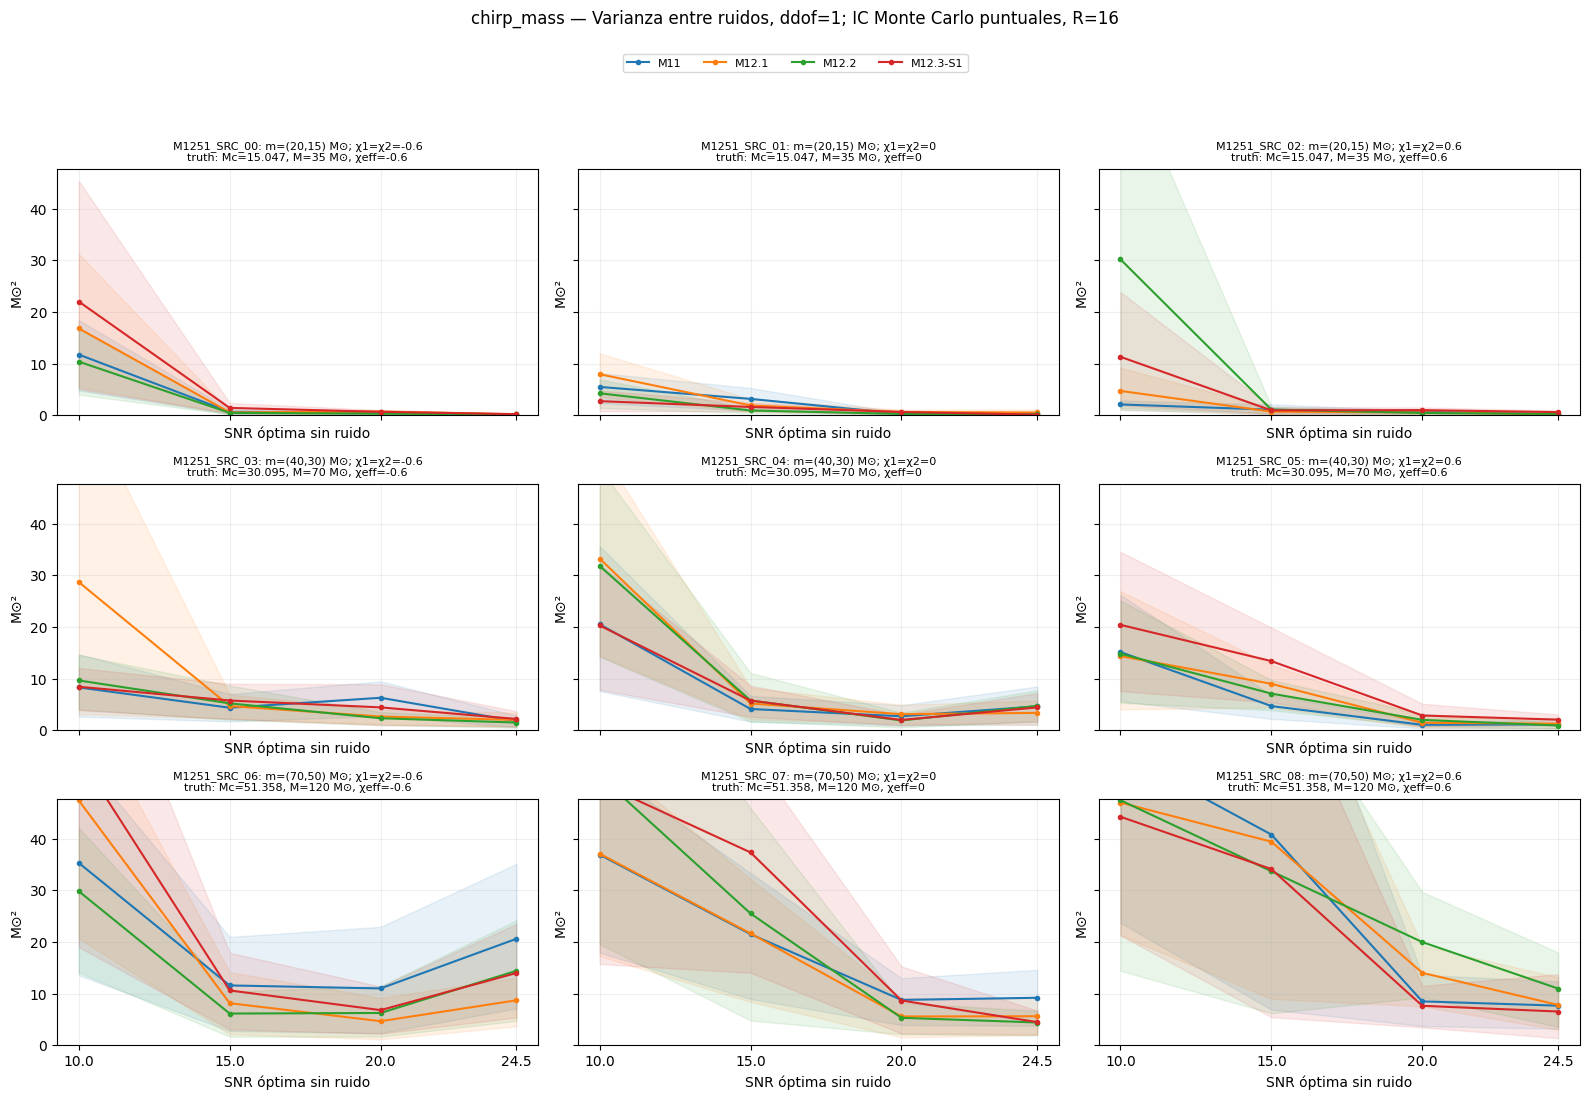

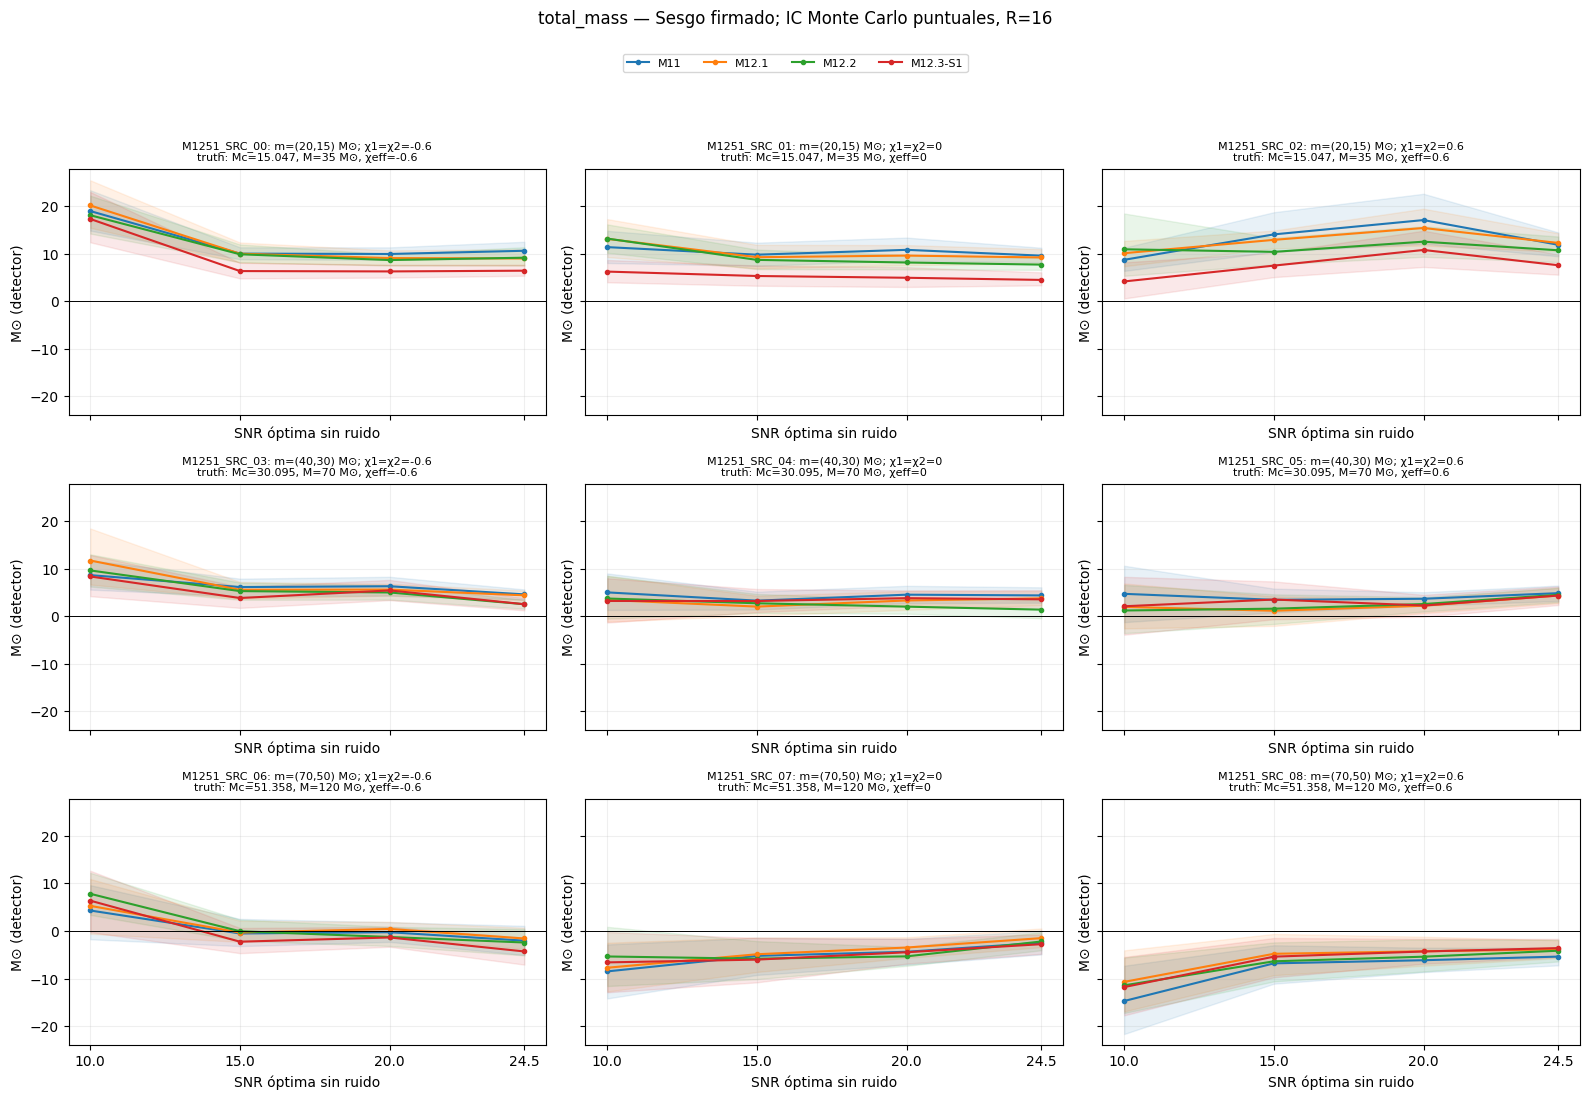

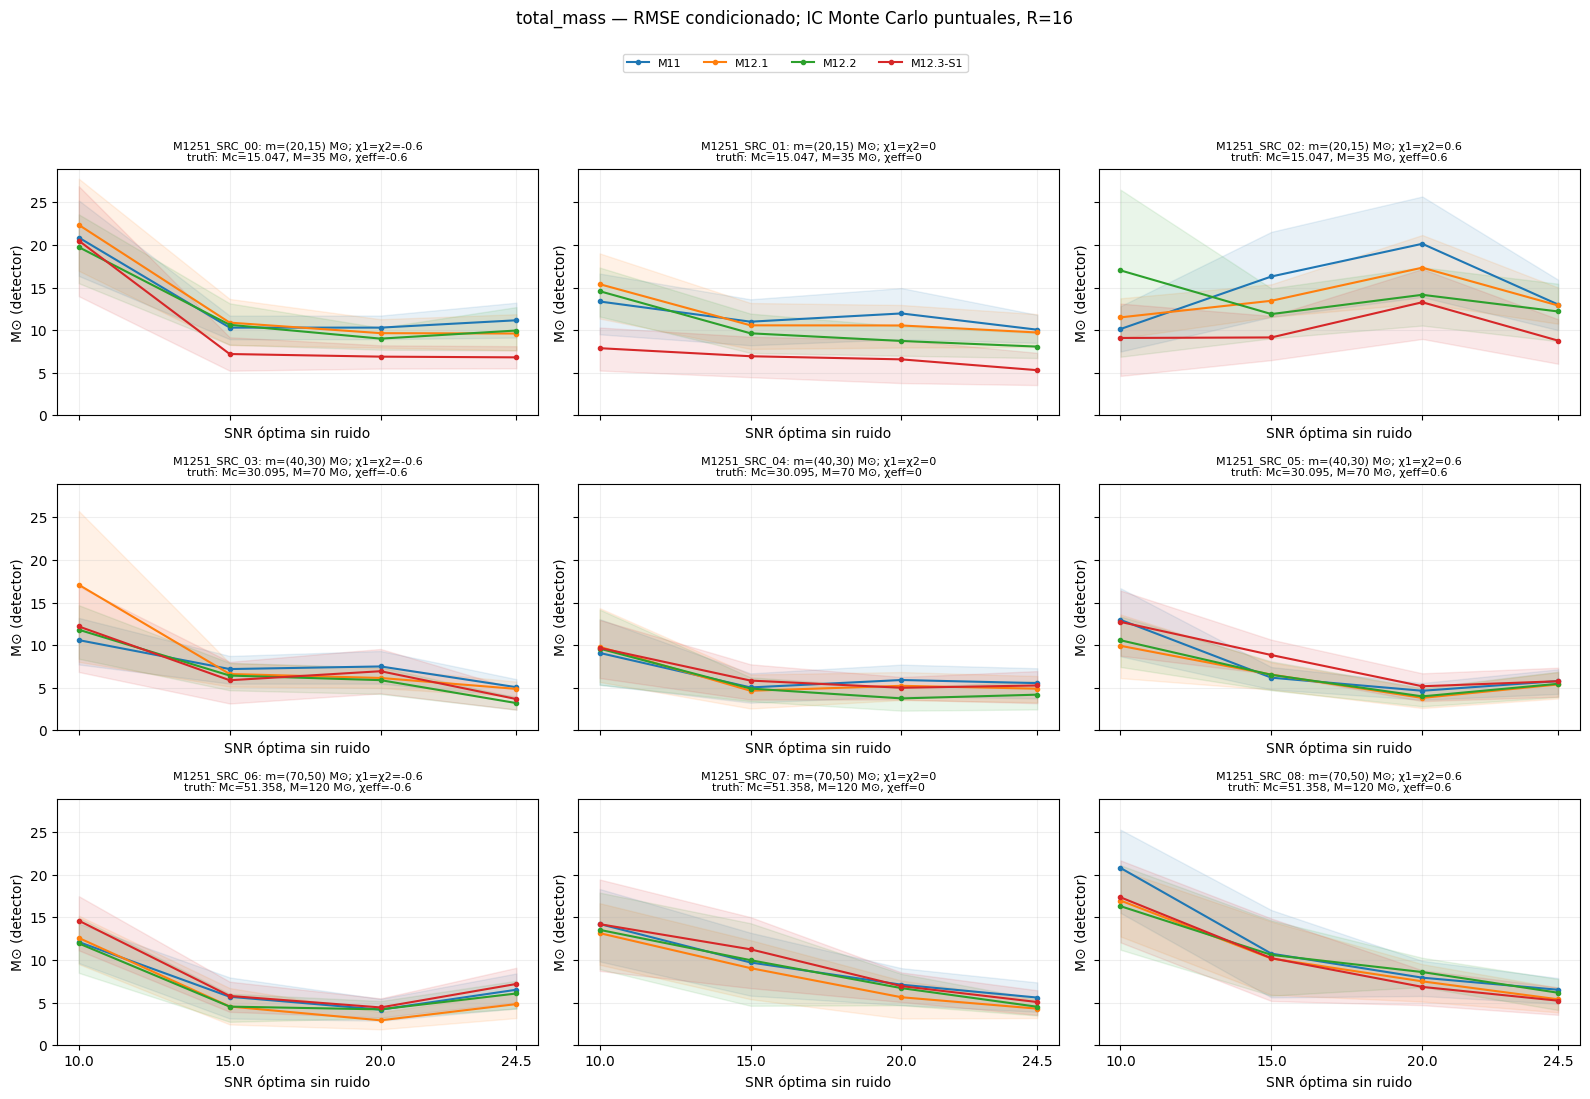

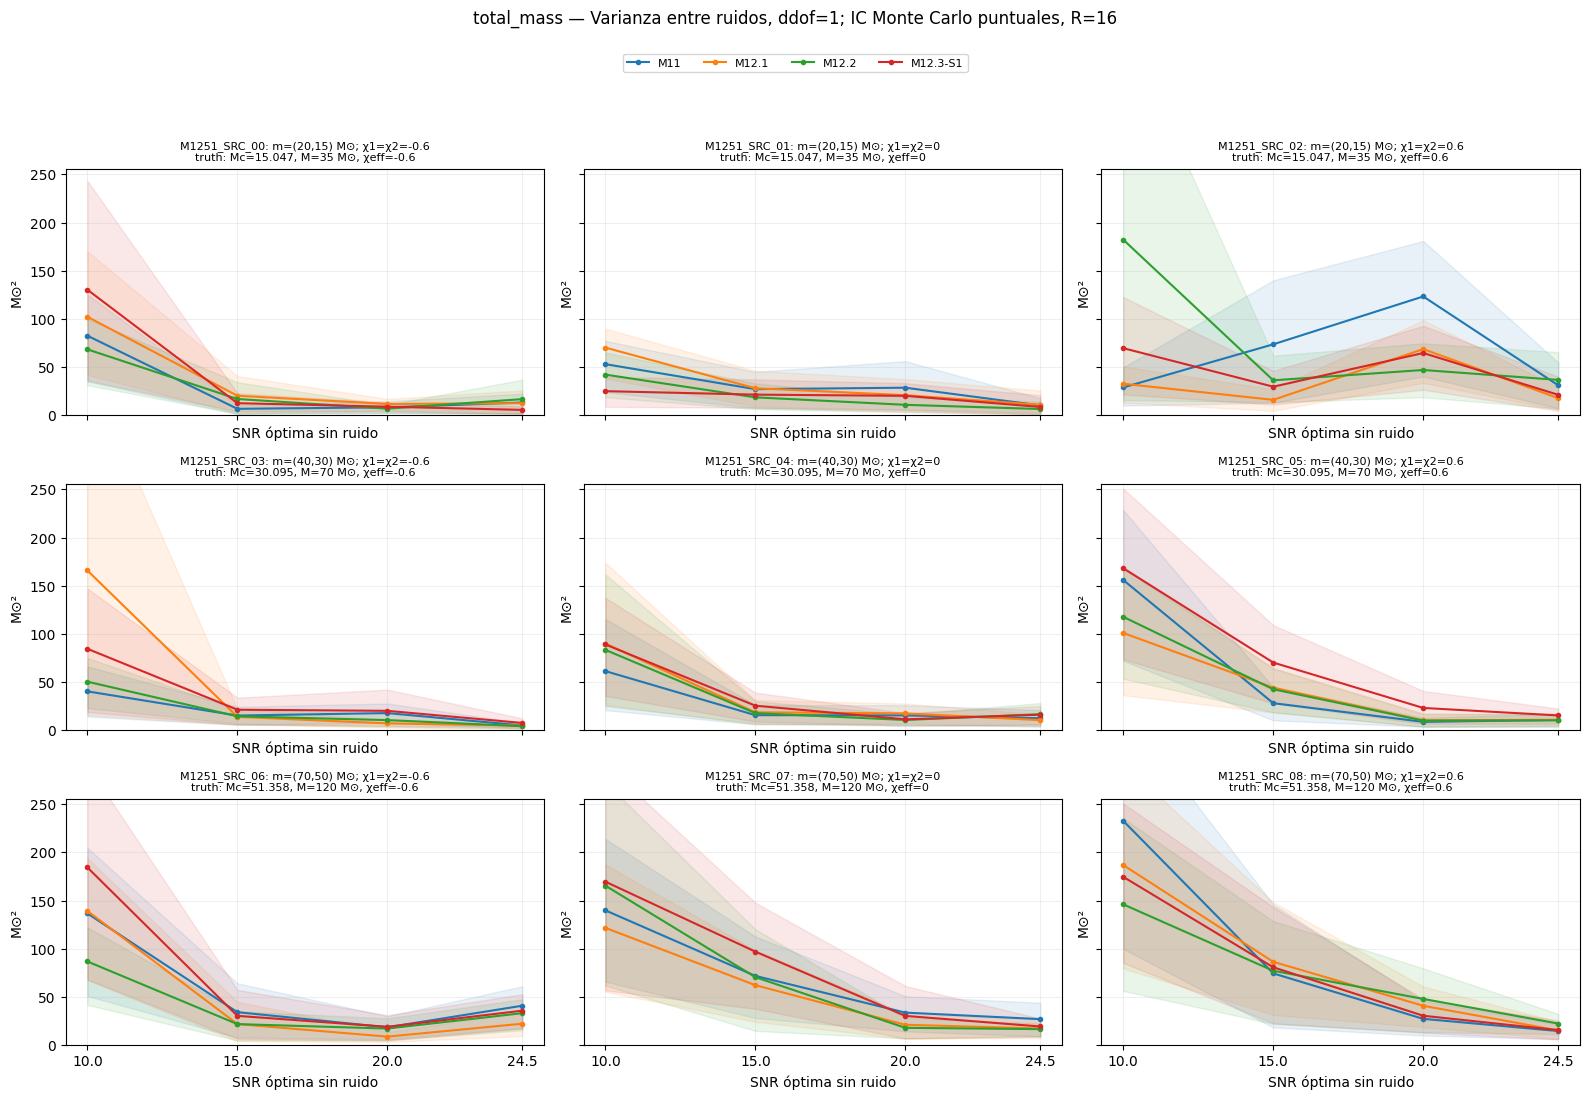

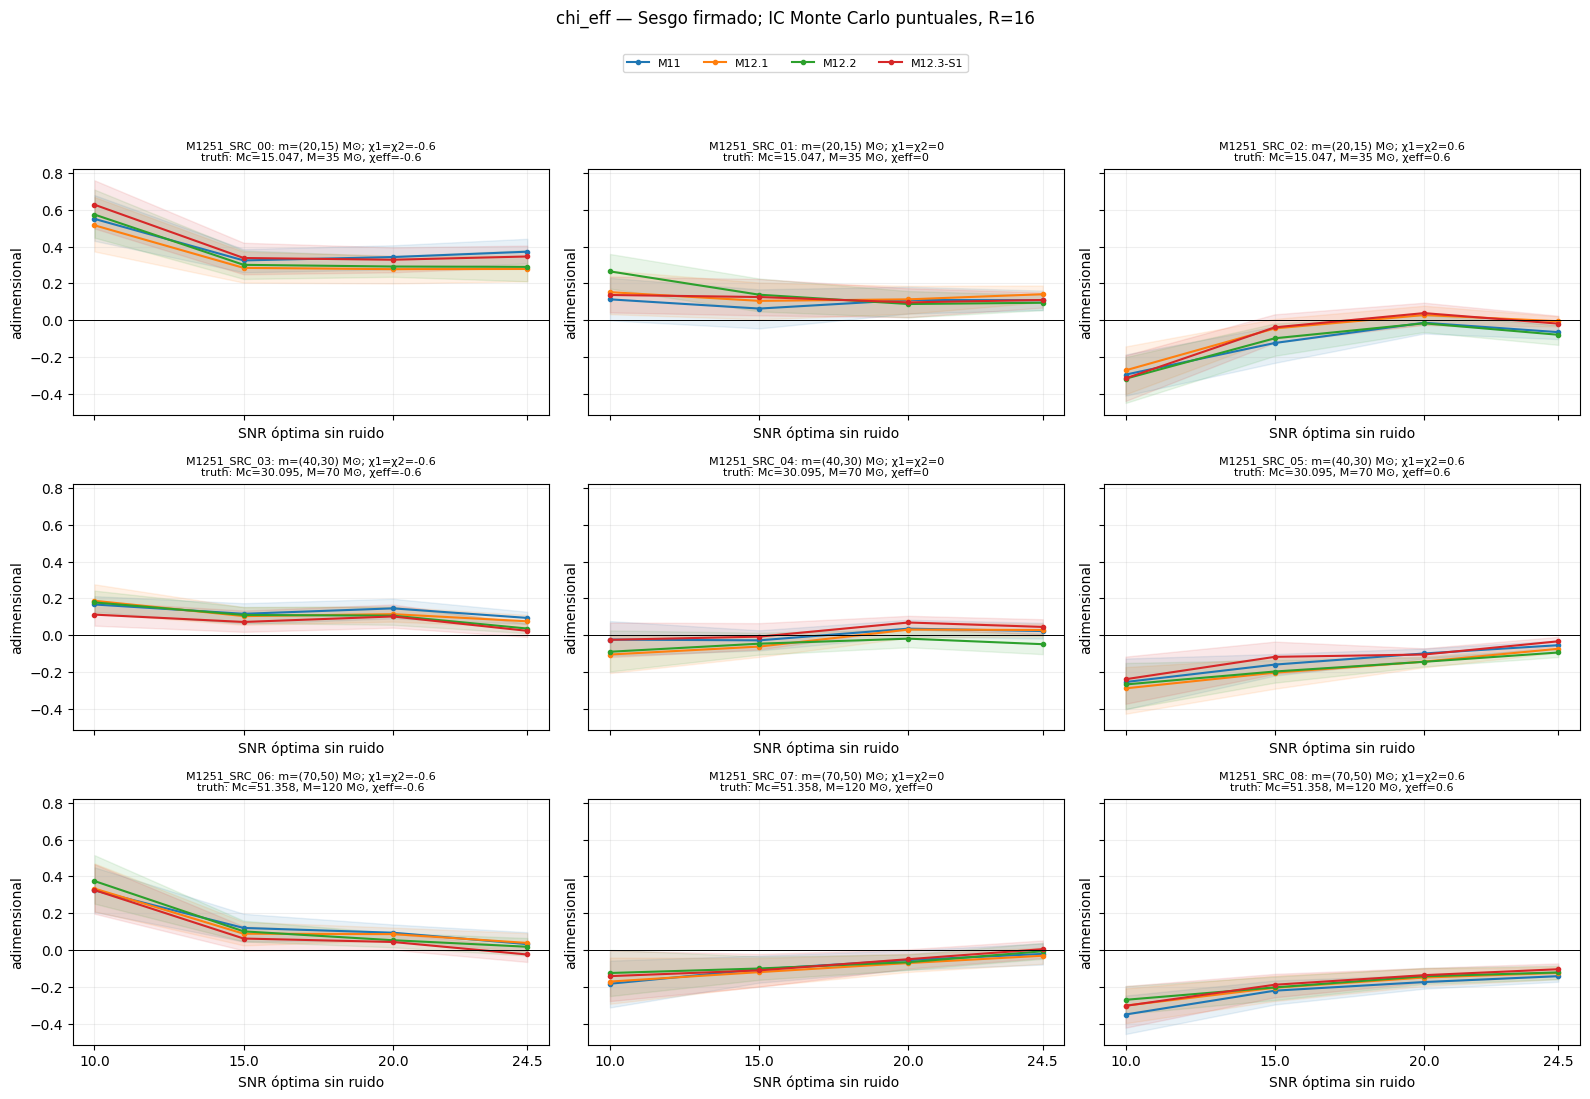

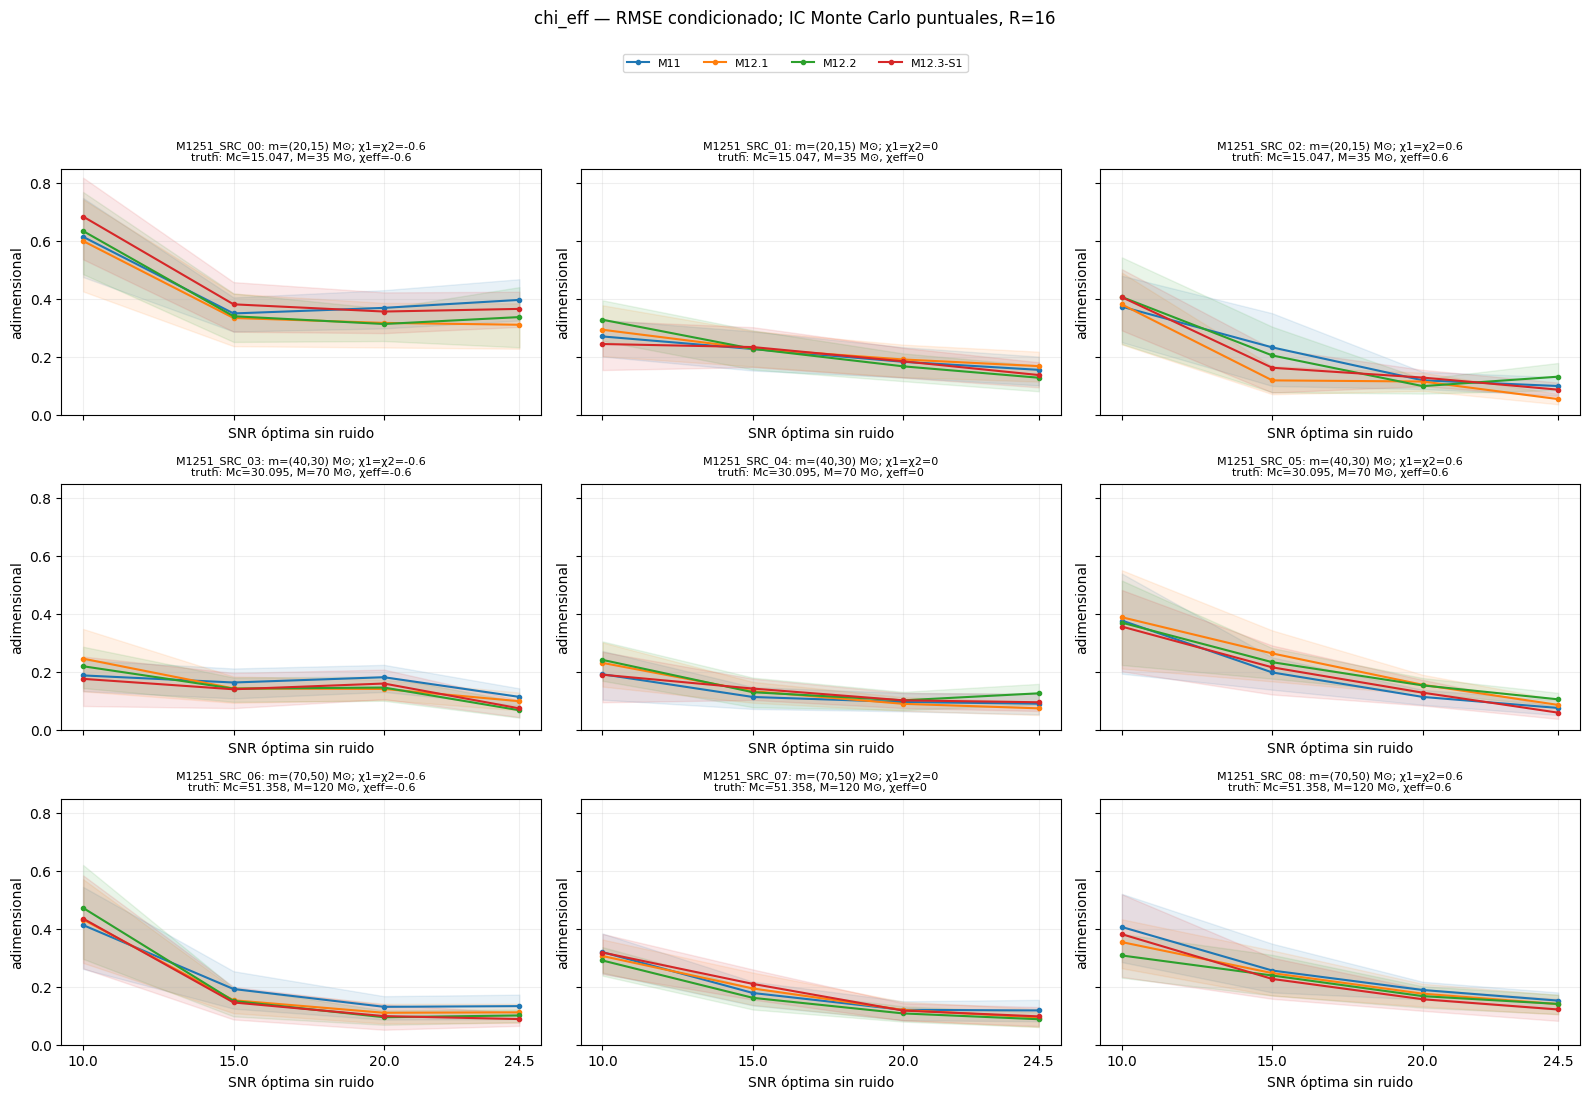

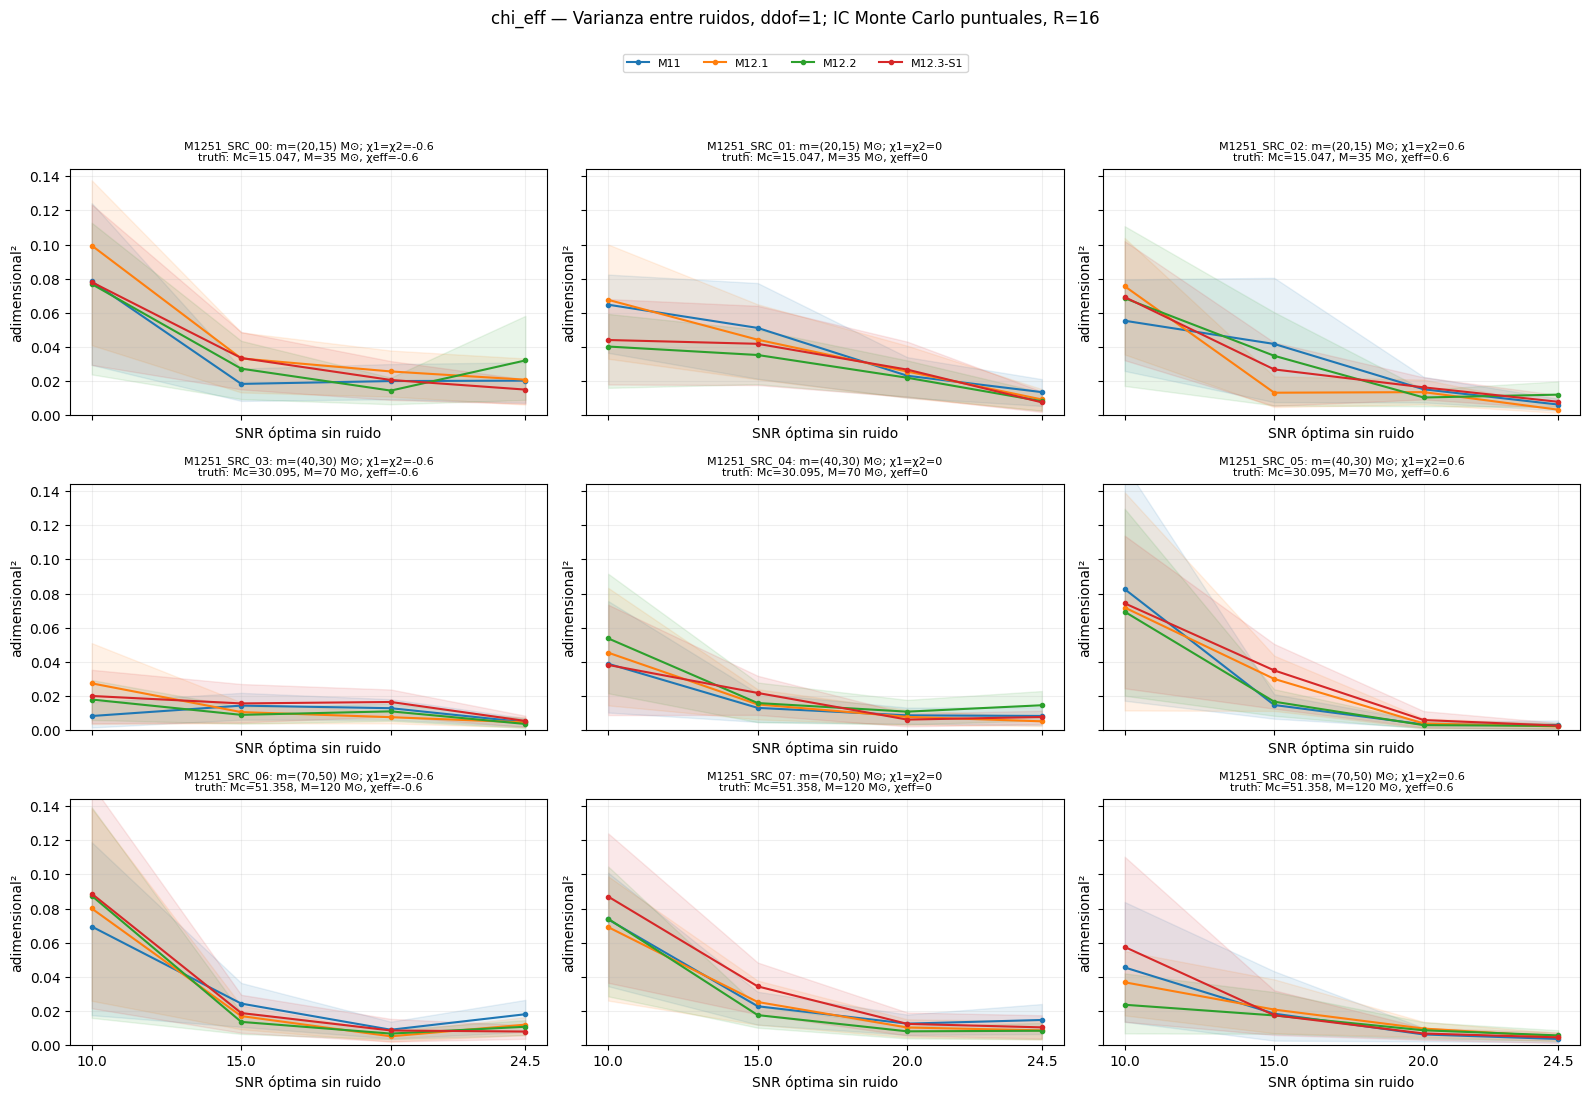

In [8]:
source_table = condition_table.drop_duplicates("source_id").set_index("source_id").loc[SOURCE_ORDER]
COLORS = dict(zip(MODEL_ORDER, plt.get_cmap("tab10").colors[:4]))
def source_title(sid):
    row = source_table.loc[sid]
    return (f"{sid}: m=({row.mass_1:g},{row.mass_2:g}) M⊙; χ1=χ2={row.spin_1z:g}\n"
            f"truth: Mc={row.true_chirp_mass:.3f}, M={row.true_total_mass:g} M⊙, χeff={row.true_chi_eff:g}")
def axis_unit(label, squared=False):
    if label == "chi_eff":
        return "adimensional²" if squared else "adimensional"
    return "M⊙²" if squared else "M⊙ (detector)"
def finish_grid(fig, axes, title, ylabel):
    for ax, sid in zip(axes.flat, SOURCE_ORDER):
        ax.set_title(source_title(sid), fontsize=8)
        ax.set_xticks(SNR_ORDER); ax.set_xlabel("SNR óptima sin ruido")
        ax.set_ylabel(ylabel); ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5,.96), ncol=4, fontsize=8)
    fig.suptitle(title, y=.995)
    fig.tight_layout(rect=(0,0,1,.92))
    plt.show(); plt.close(fig)

for label in LABEL_ORDER:
    for metric, title in (("bias", "Sesgo firmado"), ("conditional_rmse", "RMSE condicionado"),
                          ("sample_variance", "Varianza entre ruidos, ddof=1")):
        fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
        for ax, sid in zip(axes.flat, SOURCE_ORDER):
            for model in MODEL_ORDER:
                frame = exhaustive[(exhaustive.source_id == sid) & (exhaustive.label == label)
                                   & (exhaustive.model == model)].sort_values("target_snr")
                x = frame.target_snr.to_numpy()
                ax.plot(x, frame[metric].to_numpy(), "o-", color=COLORS[model], label=model, markersize=3)
                ax.fill_between(x, frame[metric+"_ci_low"].to_numpy(), frame[metric+"_ci_high"].to_numpy(),
                                color=COLORS[model], alpha=.1)
            if metric == "bias": ax.axhline(0, color="black", linewidth=.7)
            else: ax.set_ylim(bottom=0)
        finish_grid(fig, axes, f"{label} — {title}; IC Monte Carlo puntuales, R=16",
                    axis_unit(label, metric == "sample_variance"))

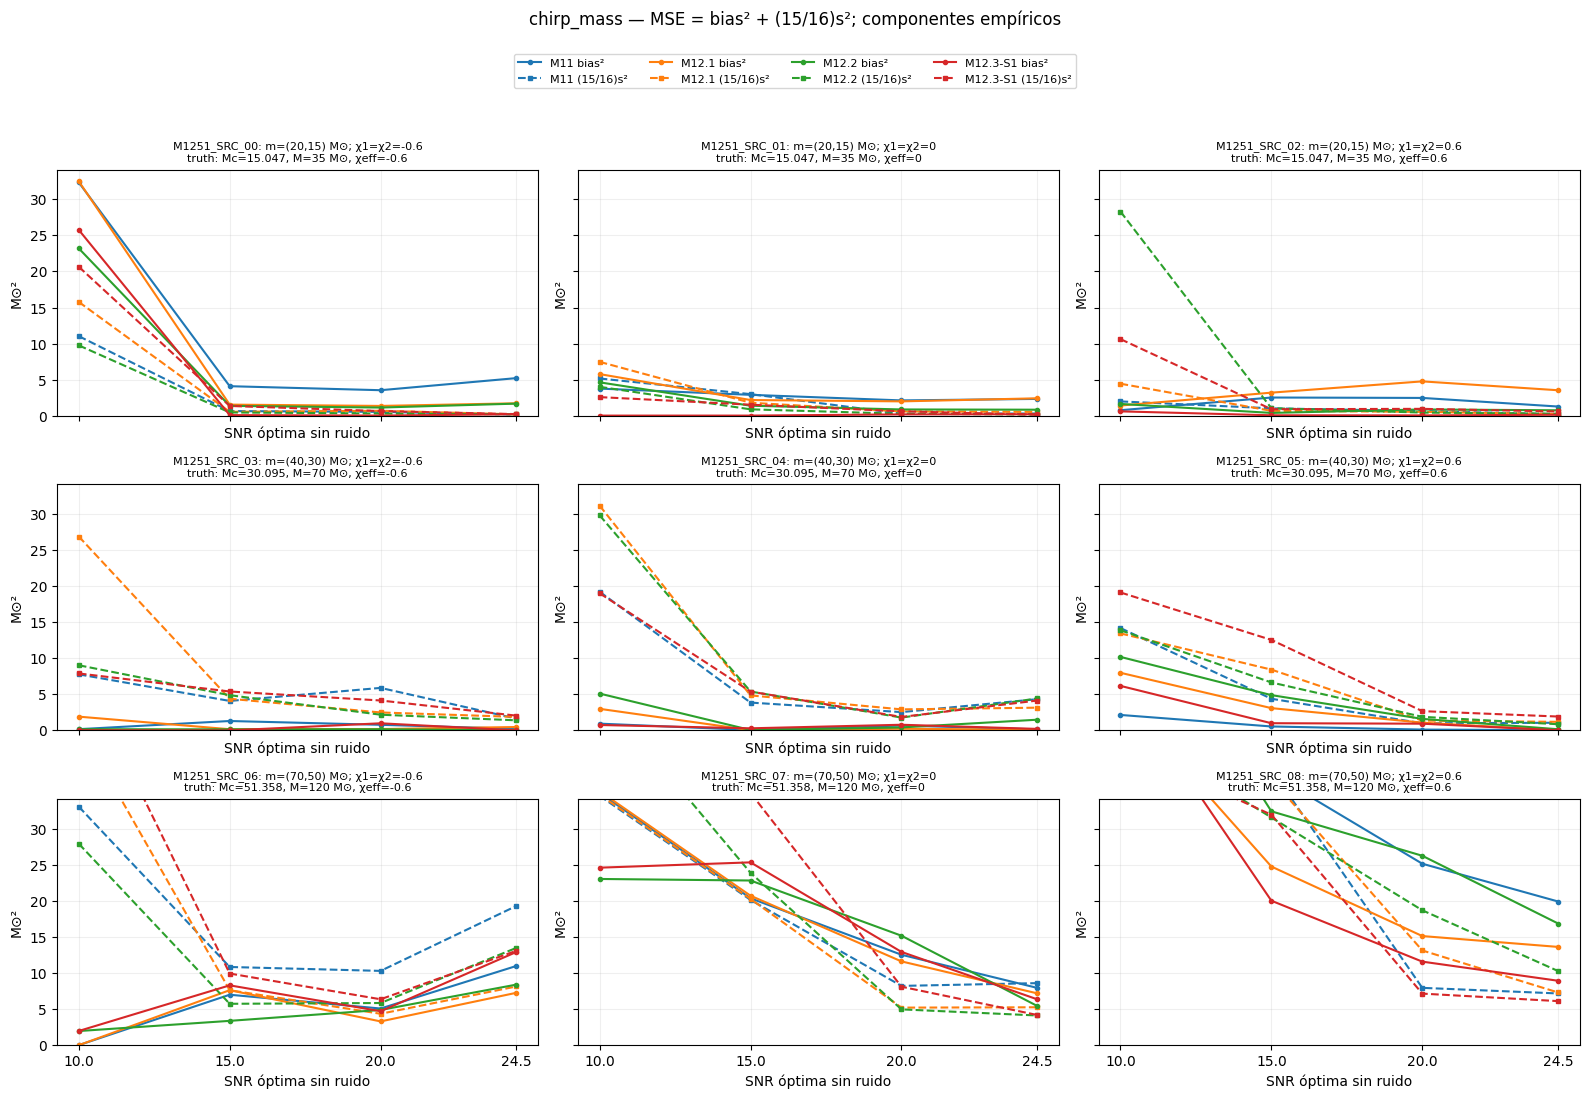

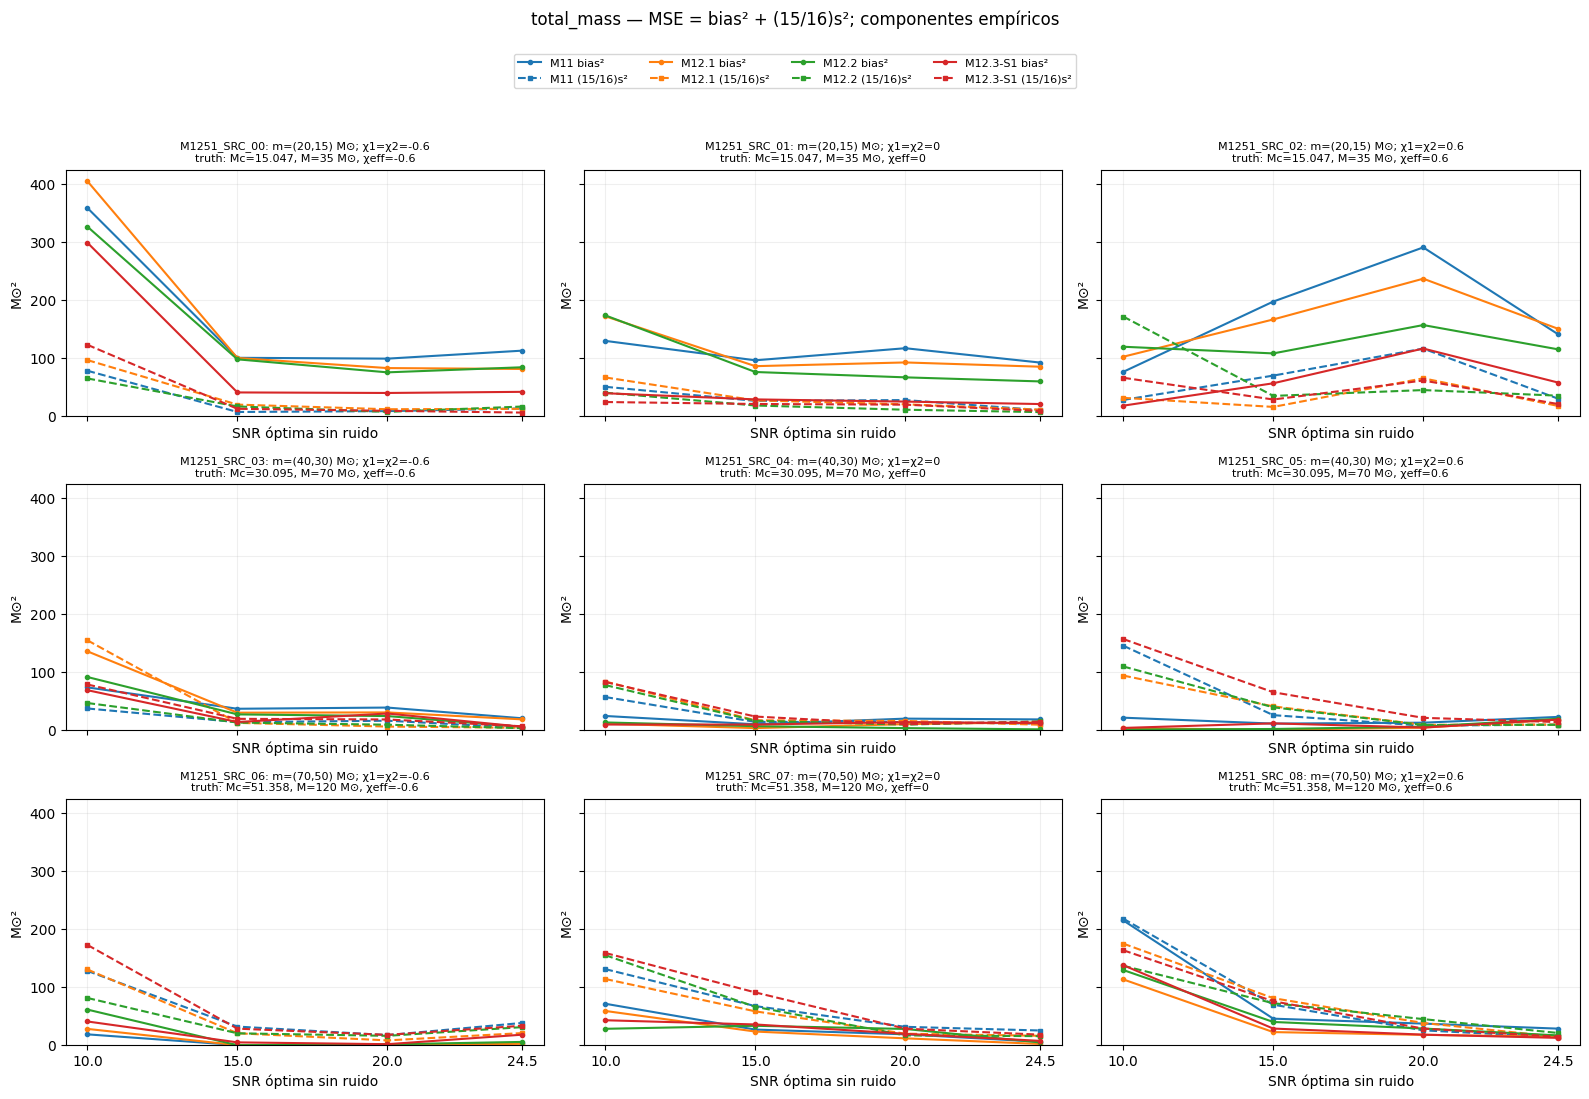

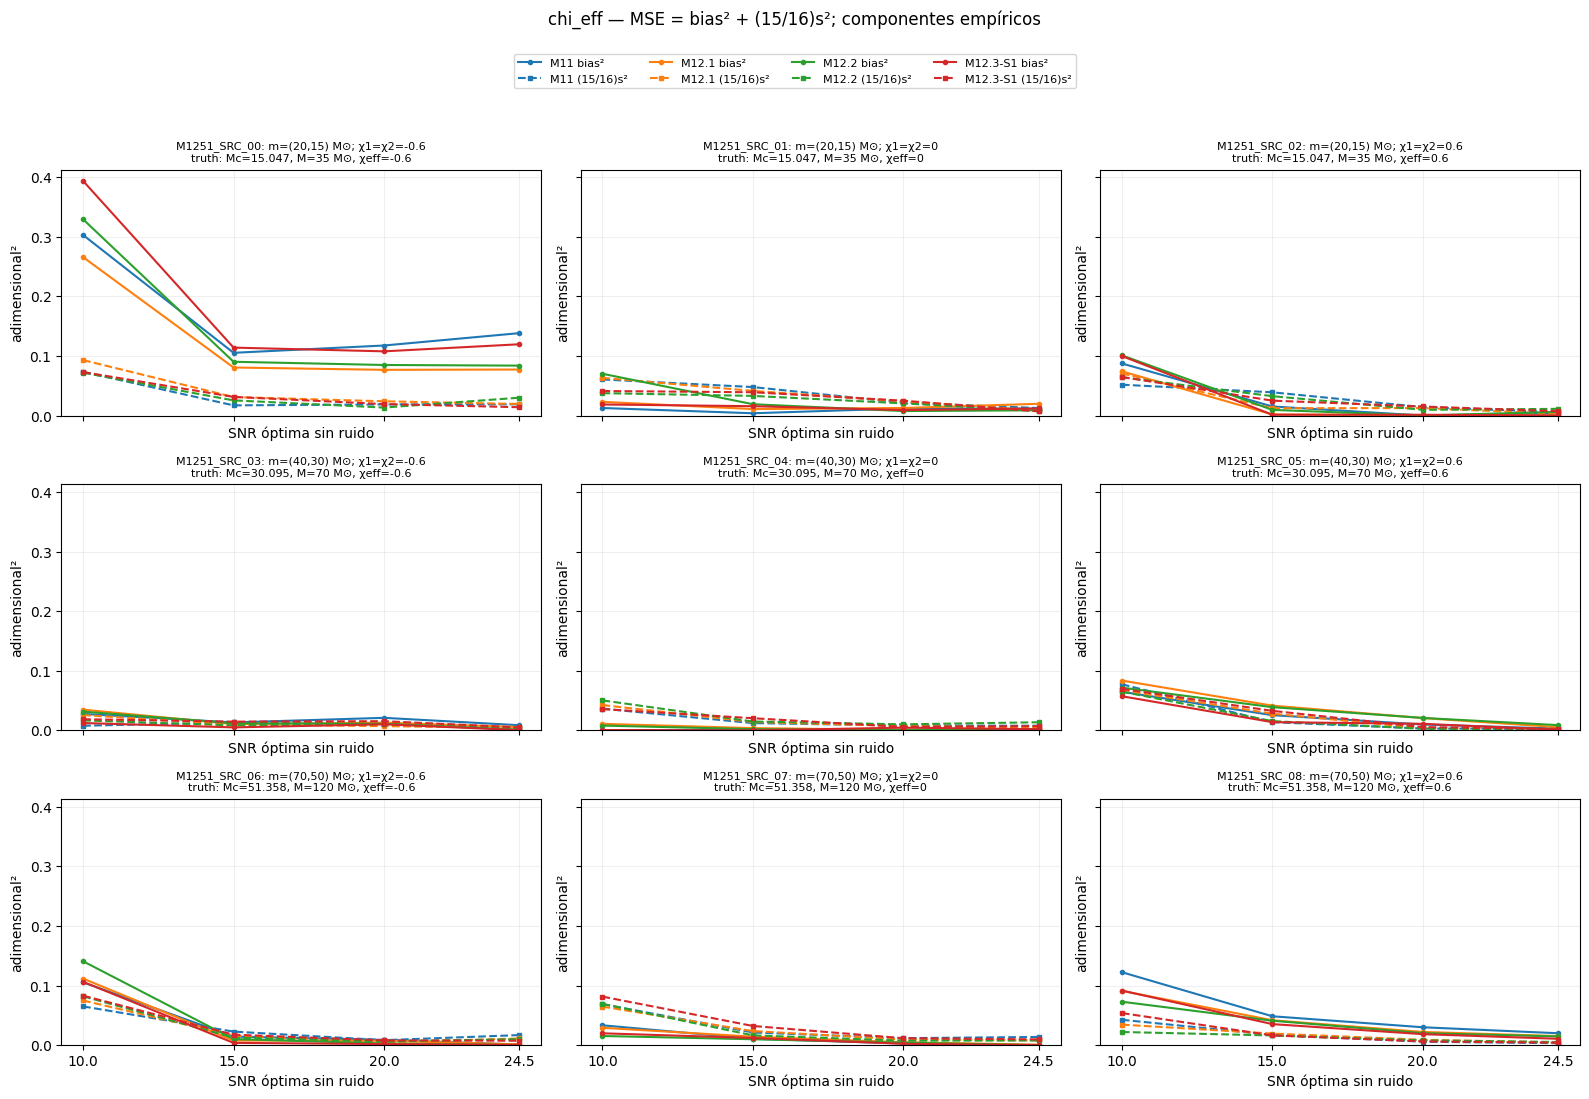

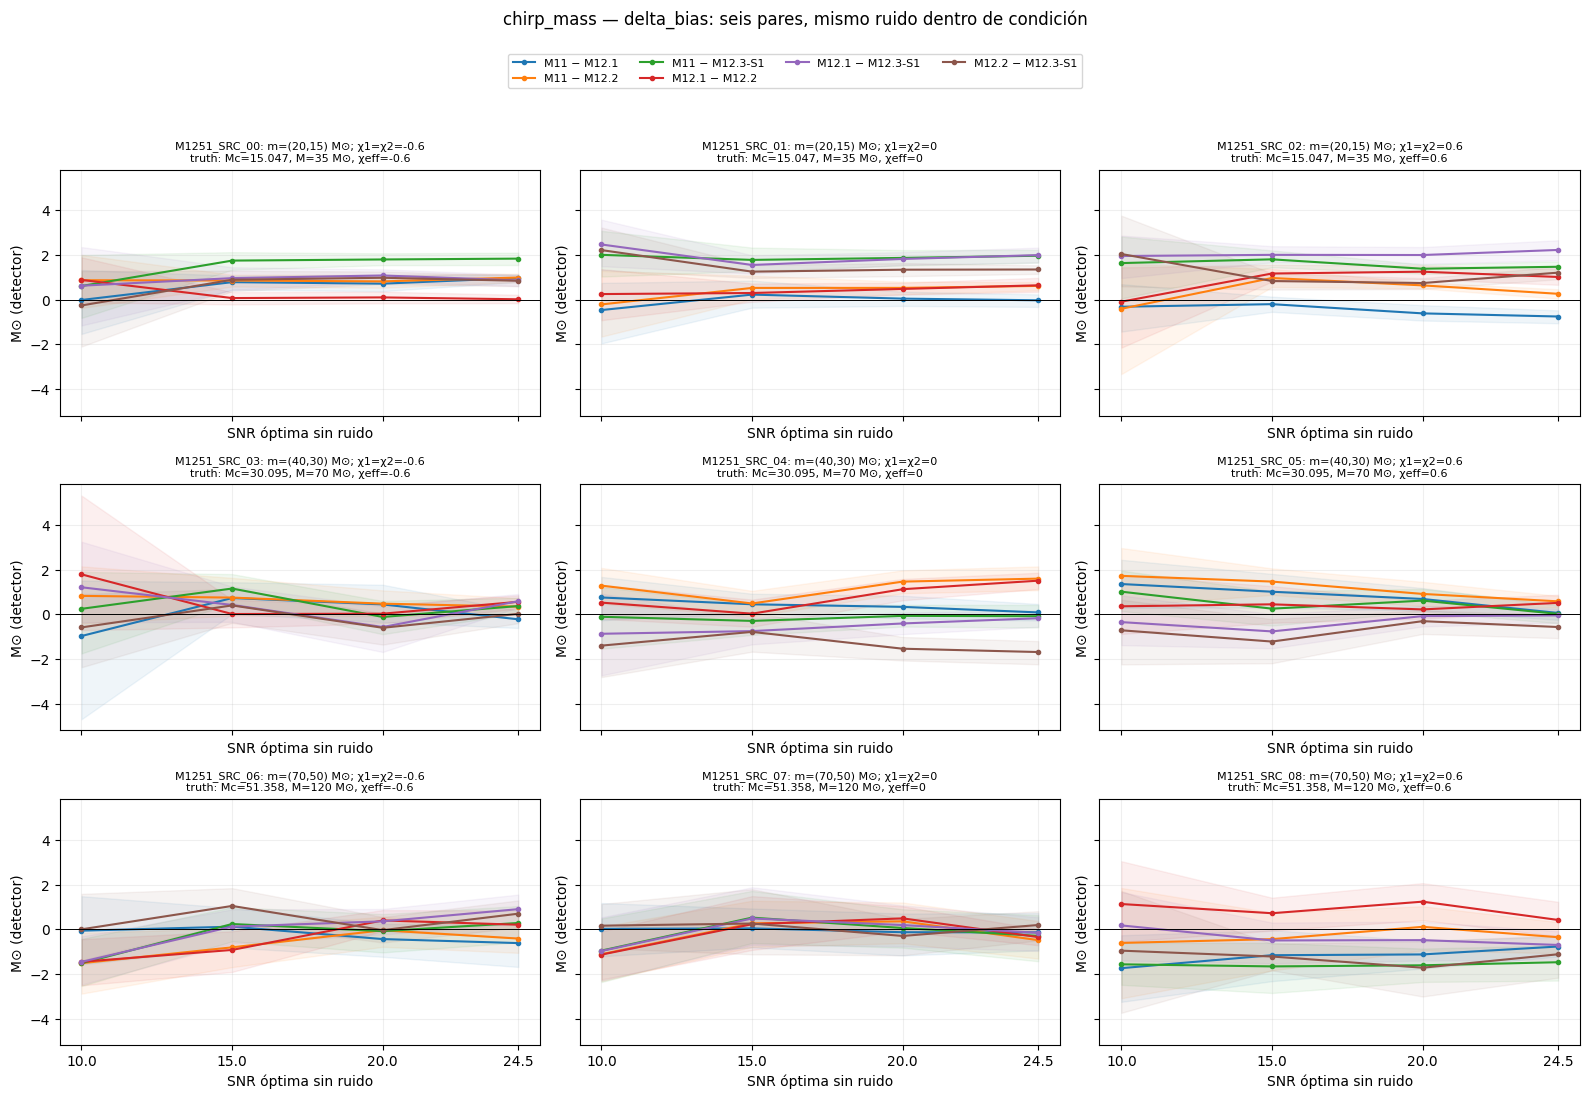

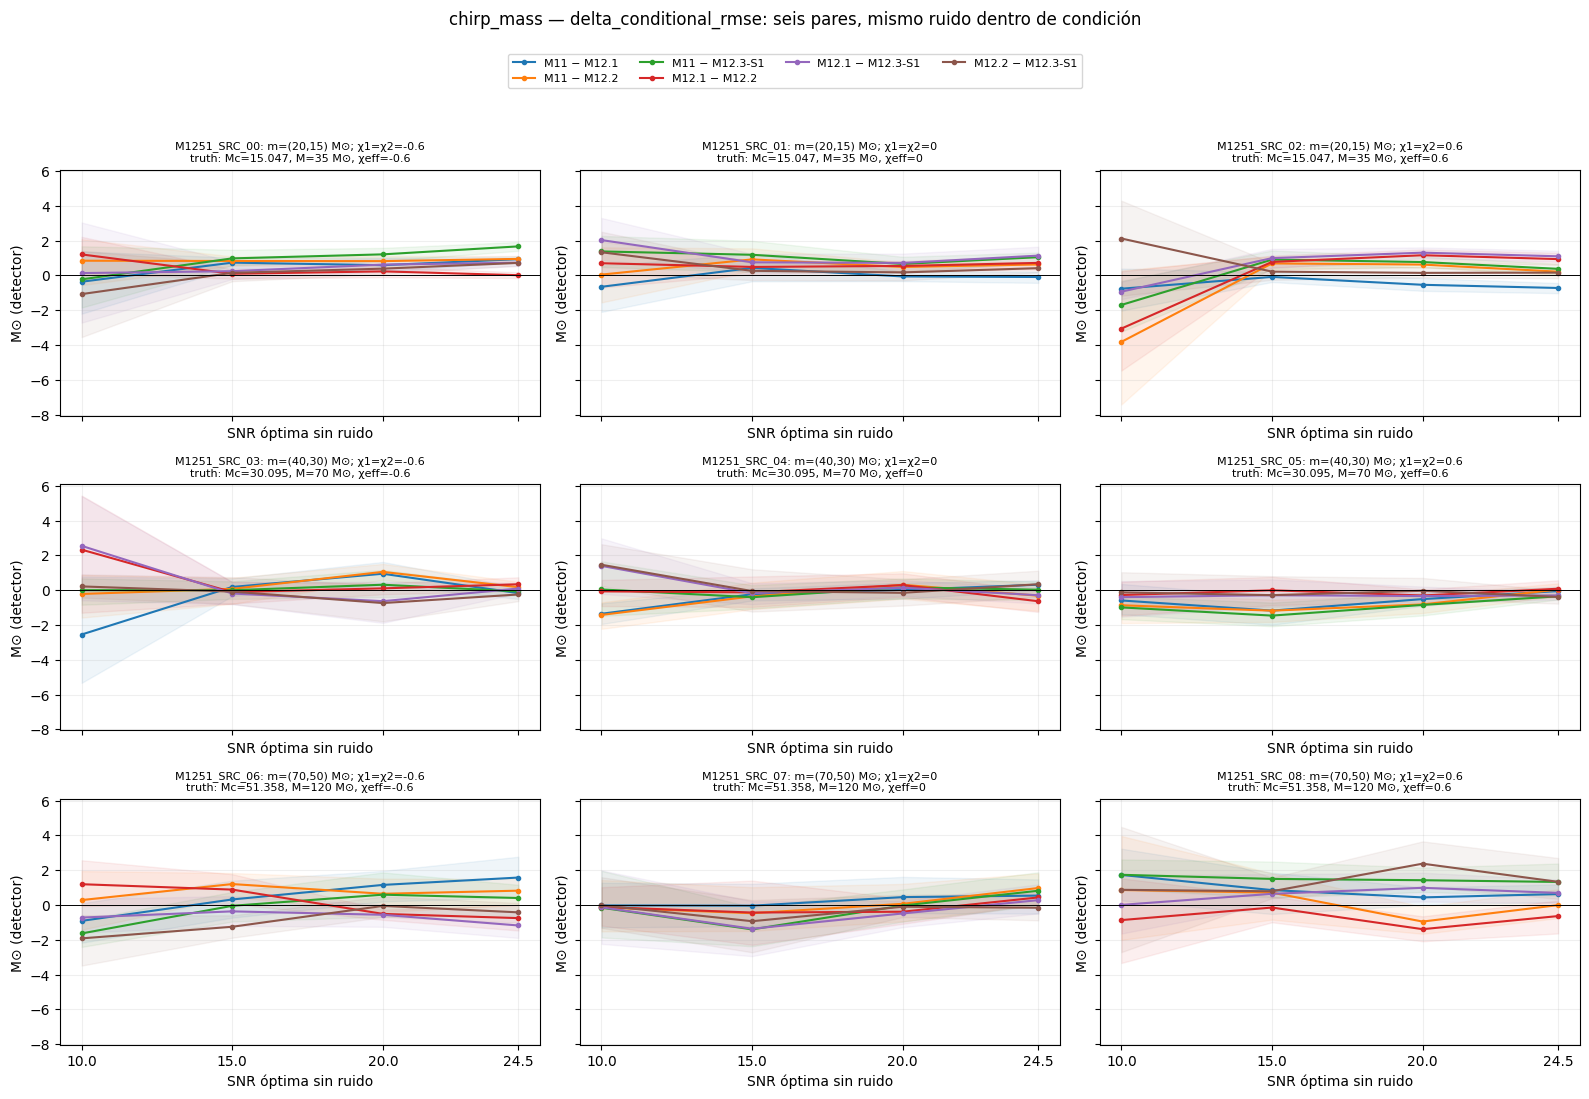

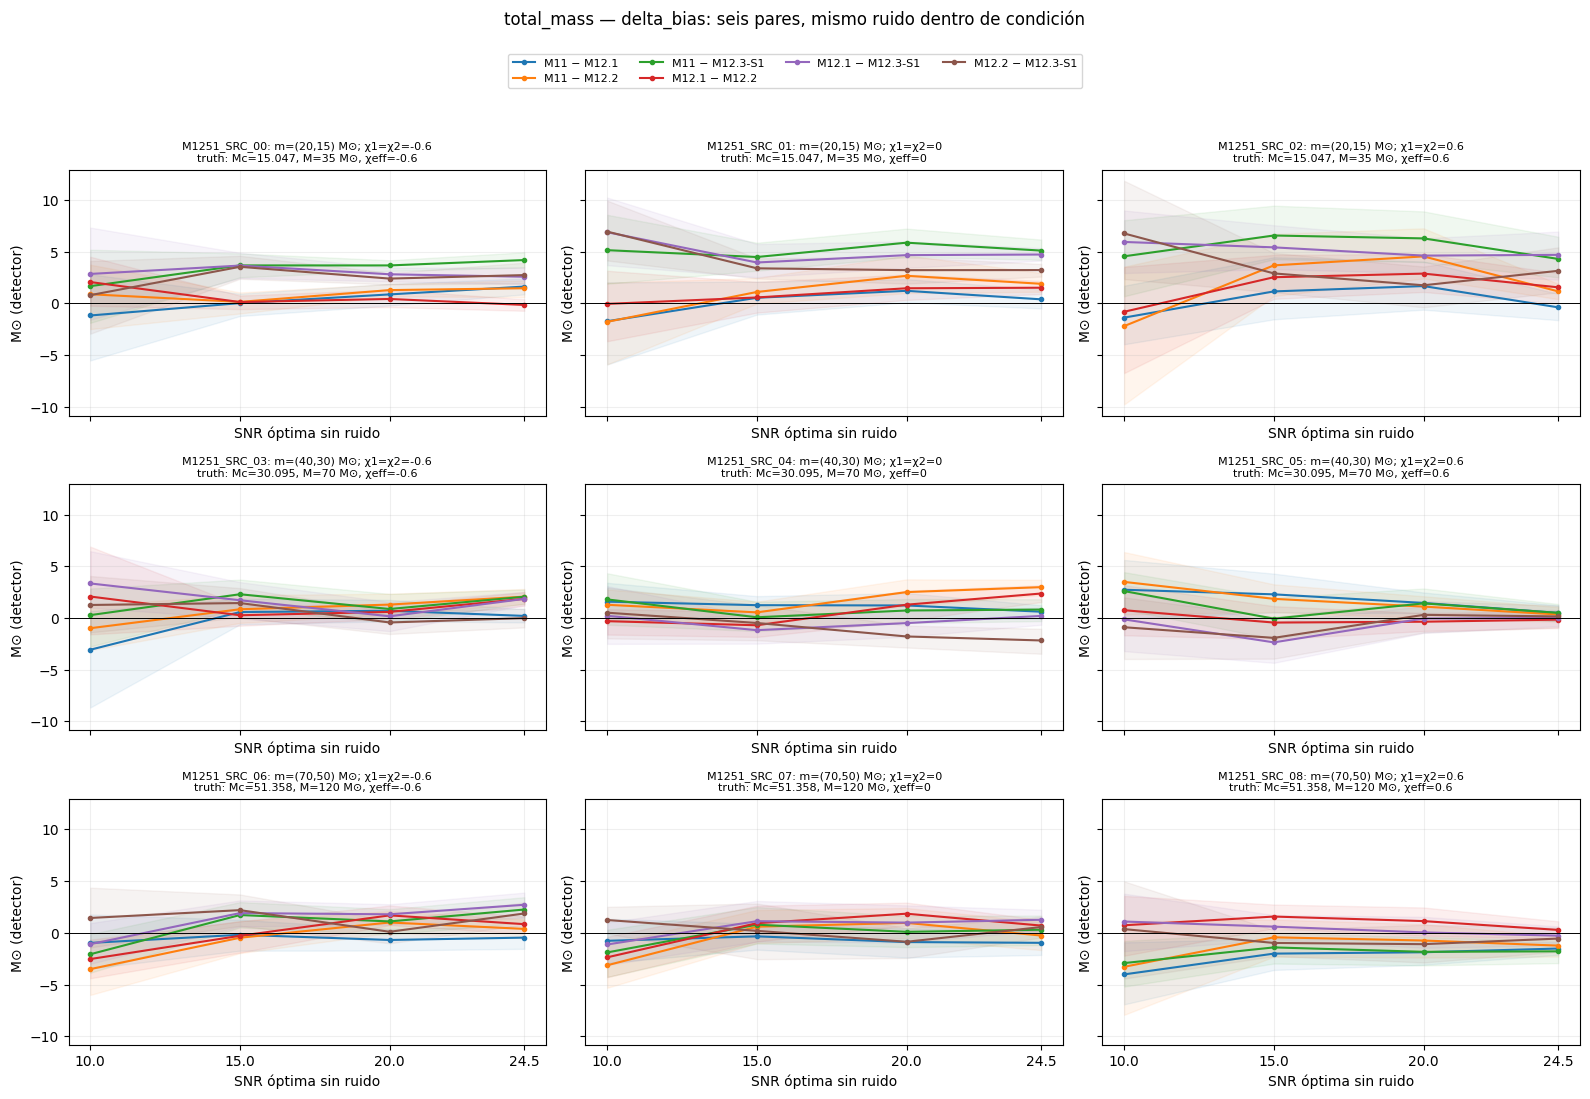

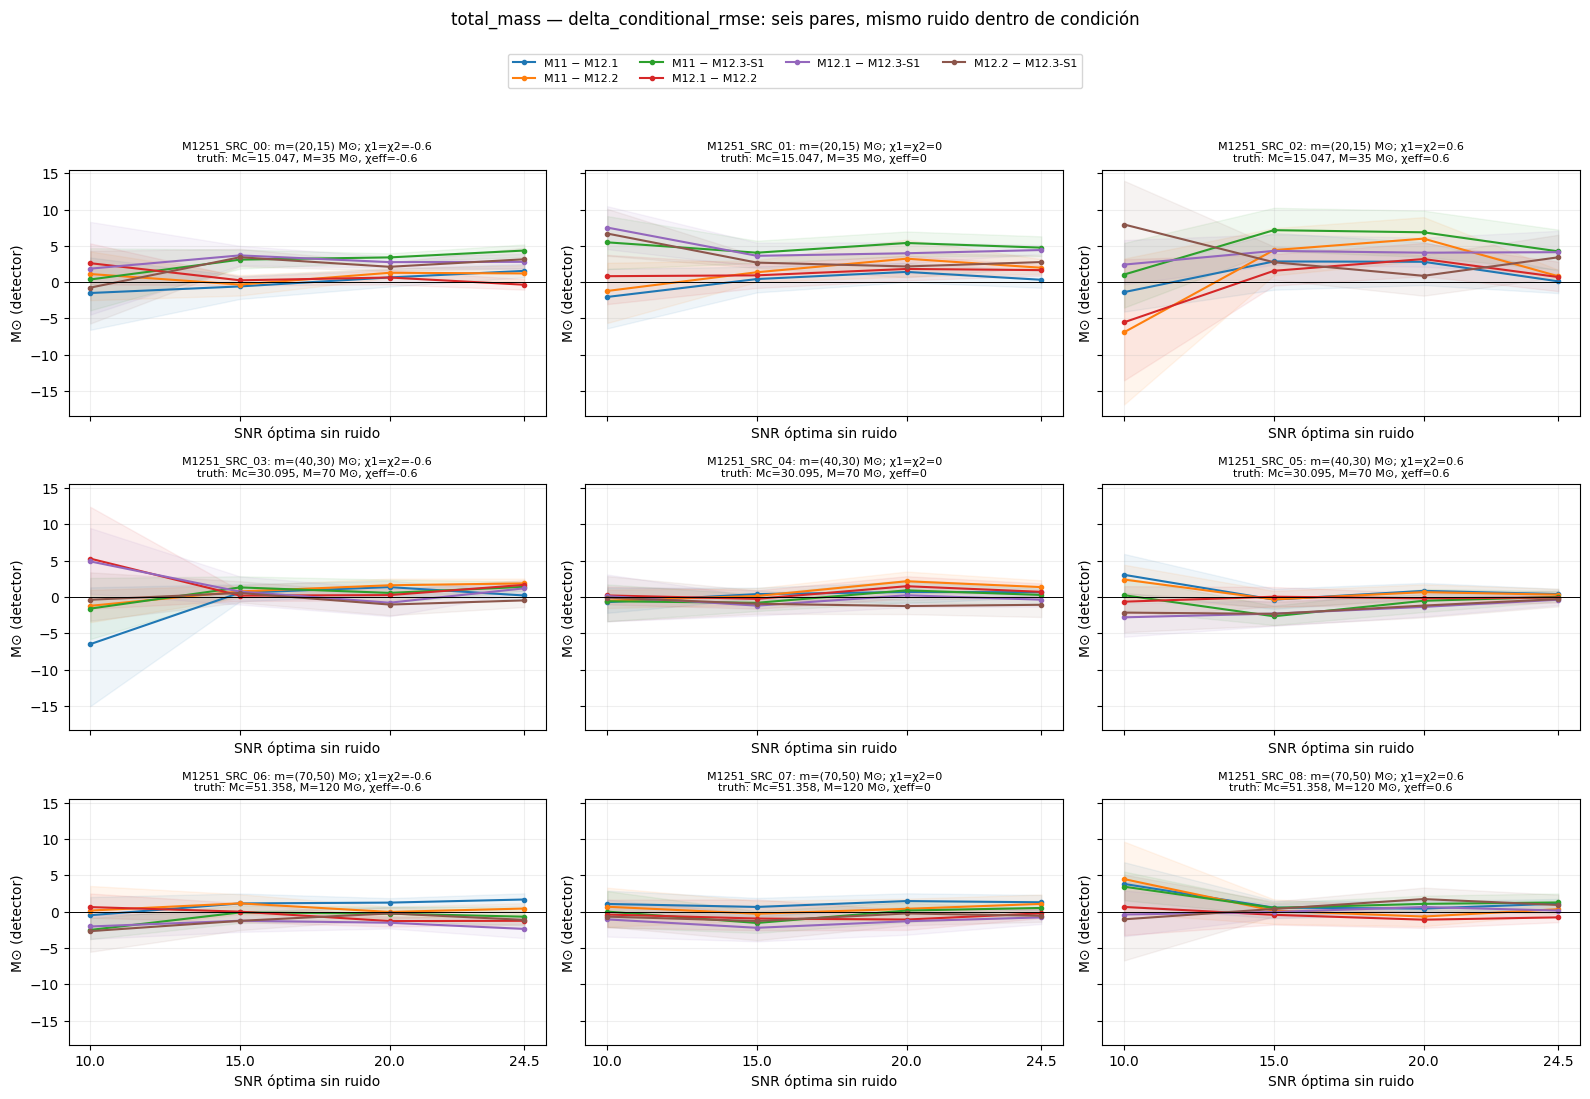

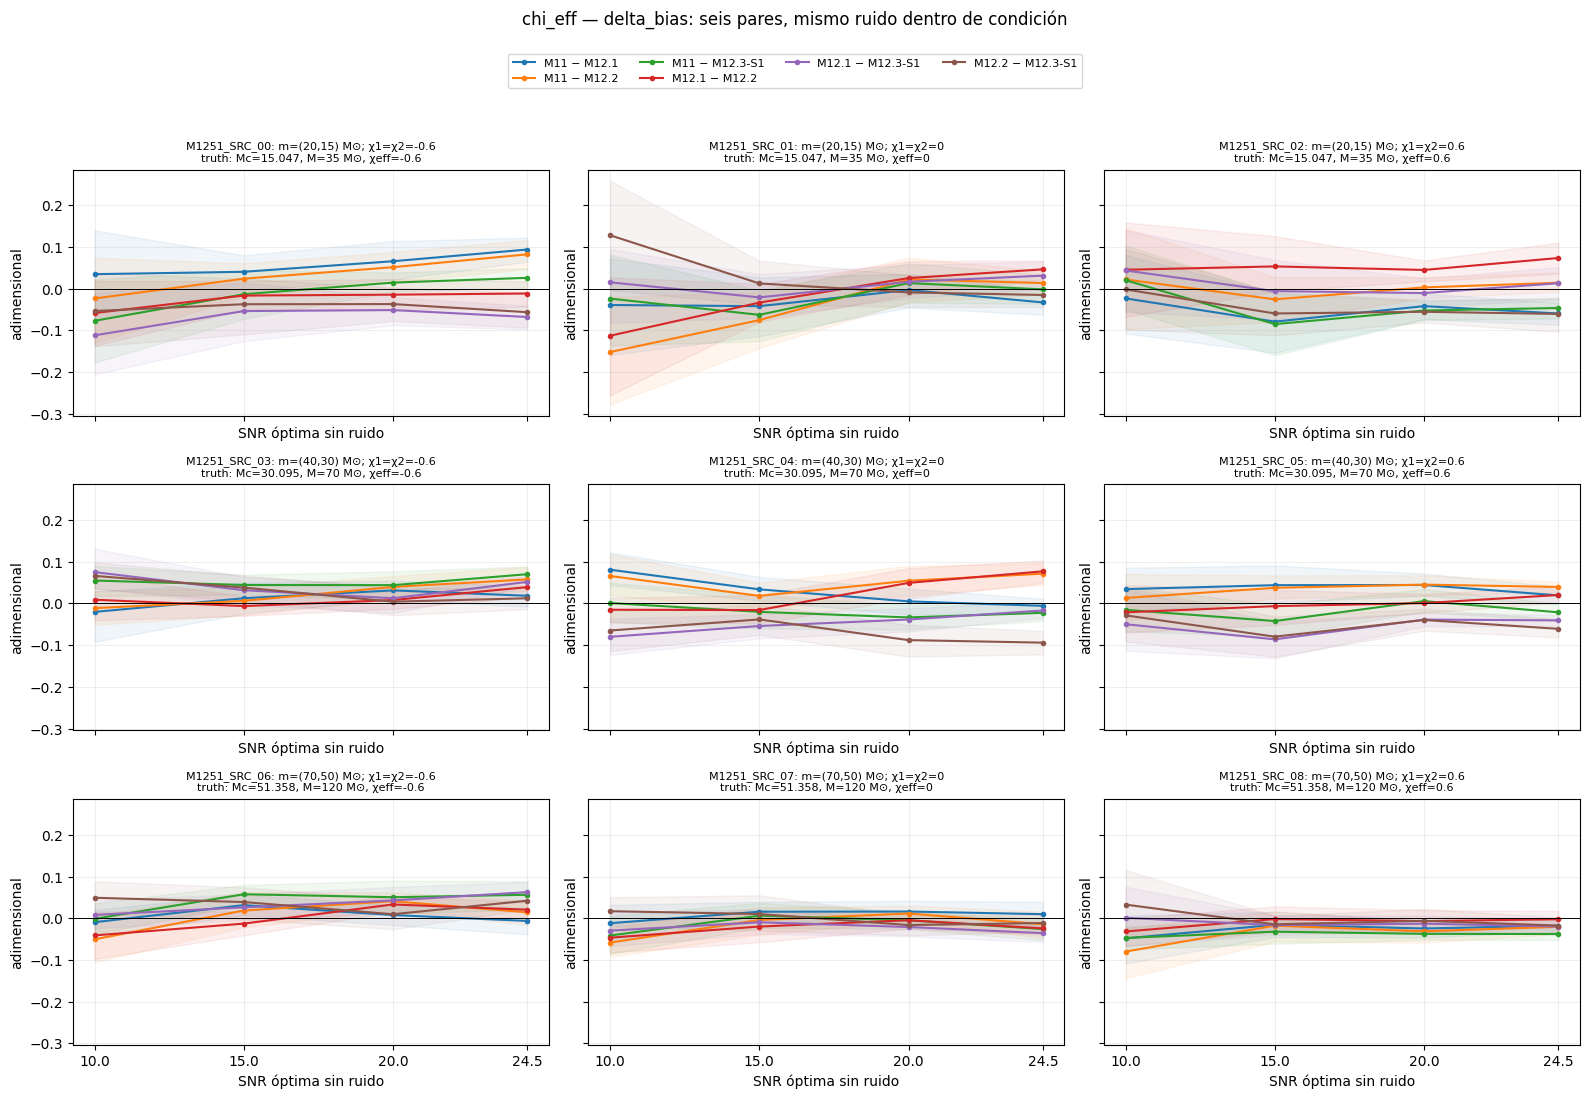

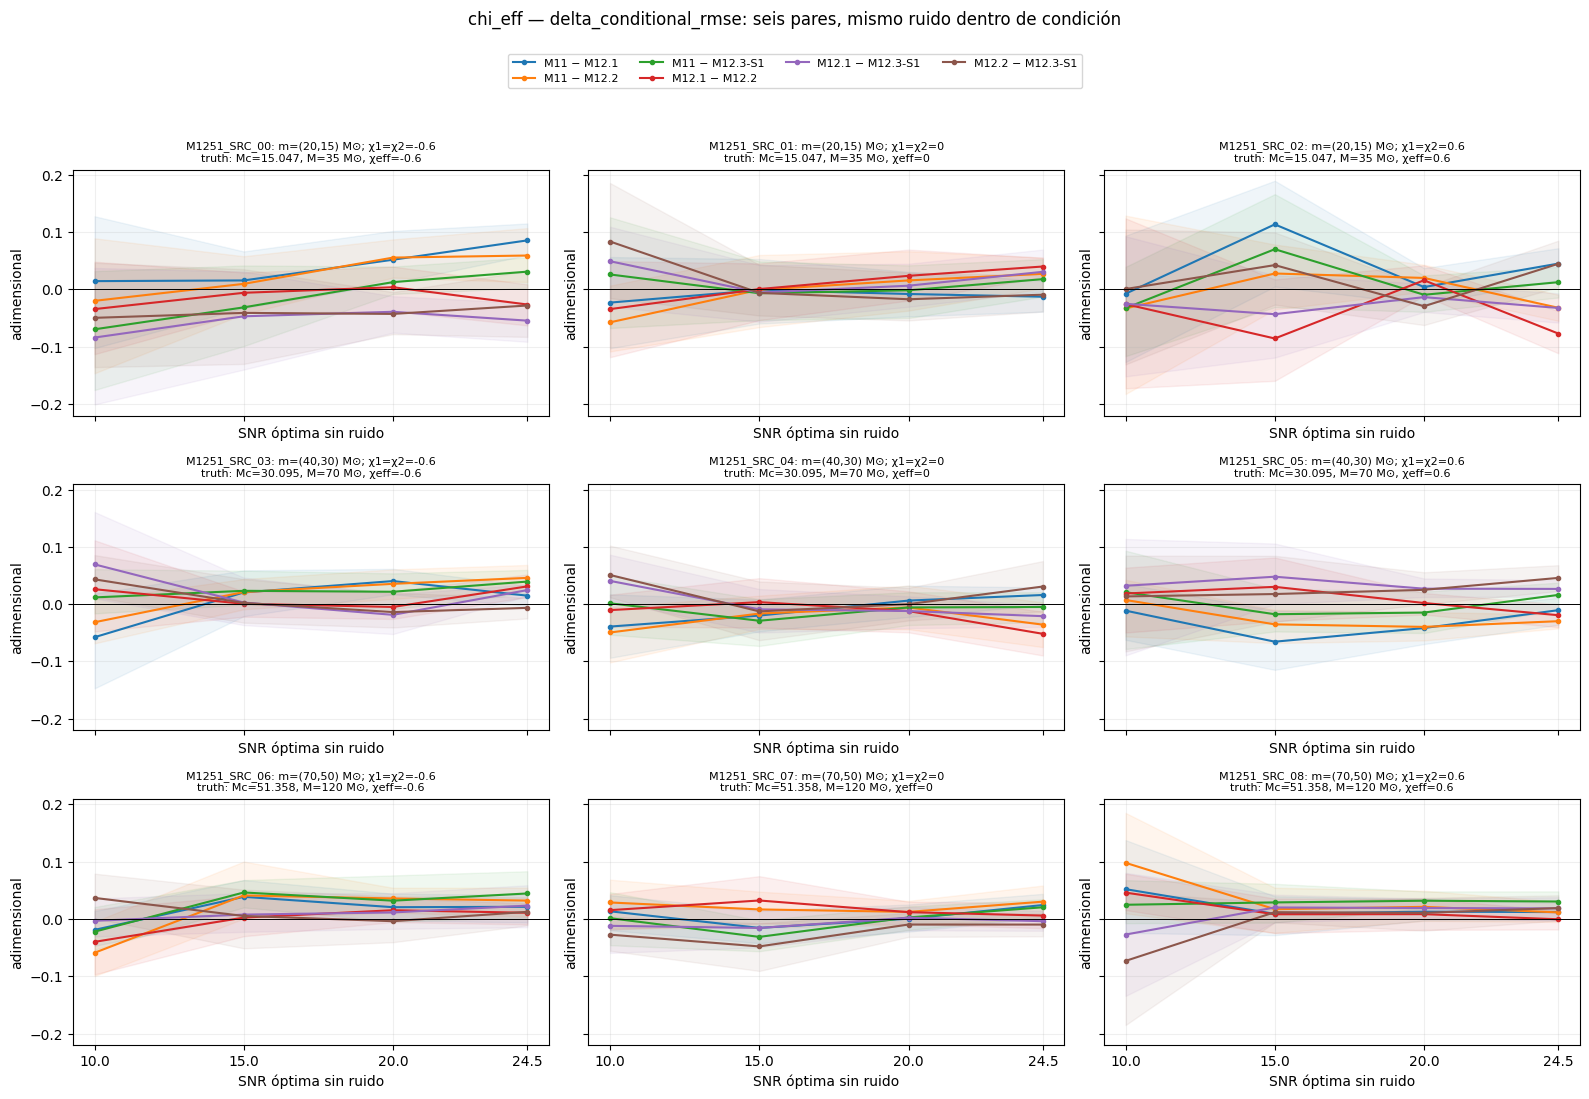

In [9]:
for label in LABEL_ORDER:
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
    for ax, sid in zip(axes.flat, SOURCE_ORDER):
        for model in MODEL_ORDER:
            frame = exhaustive[(exhaustive.source_id == sid) & (exhaustive.label == label)
                               & (exhaustive.model == model)].sort_values("target_snr")
            ax.plot(frame.target_snr, frame.bias_squared, "o-", color=COLORS[model],
                    label=model+" bias²", markersize=3)
            ax.plot(frame.target_snr, frame.finite_R_variance_component, "s--", color=COLORS[model],
                    label=model+" (15/16)s²", markersize=3)
        ax.set_ylim(bottom=0)
    finish_grid(fig, axes, f"{label} — MSE = bias² + (15/16)s²; componentes empíricos",
                axis_unit(label, squared=True))

PAIR_ORDER = list(combinations(MODEL_ORDER, 2))
PAIR_COLORS = plt.get_cmap("tab10").colors[:6]
for label in LABEL_ORDER:
    for metric in ("delta_bias", "delta_conditional_rmse"):
        fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
        for ax, sid in zip(axes.flat, SOURCE_ORDER):
            for color, (a,b) in zip(PAIR_COLORS, PAIR_ORDER):
                frame = paired_full[(paired_full.source_id == sid) & (paired_full.label == label)
                                    & (paired_full.model_a == a) & (paired_full.model_b == b)].sort_values("target_snr")
                x = frame.target_snr.to_numpy()
                ax.plot(x, frame[metric].to_numpy(), "o-", color=color, label=a+" − "+b, markersize=3)
                ax.fill_between(x, frame[metric+"_ci_low"].to_numpy(), frame[metric+"_ci_high"].to_numpy(),
                                color=color, alpha=.07)
            ax.axhline(0, color="black", linewidth=.7)
        finish_grid(fig, axes, f"{label} — {metric}: seis pares, mismo ruido dentro de condición",
                    axis_unit(label))

### Contracción descriptiva respecto a las medias train G1

Se usan exclusivamente las medias y escalas congeladas en los recibos de checkpoints, sin ajustar referencias nuevas. Se distinguen: dirección inicial hacia la media (`bias * (mu_train−truth)>0`), acercamiento efectivo a esa media (reducción de distancia absoluta) y sobrepaso de la media. La razón `bias/(mu_train−truth)` describe contracción (0: verdad; 1: media train); puede ser negativa o superar uno. Se omite cuando la verdad dista menos del 1% de la desviación train de la media, umbral descriptivo prefijado que evita divisiones mal condicionadas, particularmente para χeff=0.

Esto no prueba Bayes-optimalidad ni identifica el prior posterior efectivo. Las nueve fuentes diseñadas no son representativas de G1; no deben usarse estos resultados como pendientes o tasas de contracción poblacionales.

,source_id,target_snr,model,label,truth,G1_train_mean,mean_prediction,near_train_mean,bias_points_toward_mean,distance_to_train_mean_reduction,crossed_train_mean,contraction_ratio,contraction_ratio_ci_low,contraction_ratio_ci_high
0,M1251_SRC_00,10.0,M11,chi_eff,-0.600000,-0.000219,-0.049426,False,True,0.550574,False,0.917959,0.718920,1.132889
1,M1251_SRC_00,10.0,M11,chirp_mass,15.047320,37.463547,20.735323,False,True,5.688003,False,0.253745,0.182140,0.329311
2,M1251_SRC_00,10.0,M11,total_mass,35.000000,94.985977,53.924992,False,True,18.924992,False,0.315490,0.247071,0.388356
3,M1251_SRC_00,10.0,M12.1,chi_eff,-0.600000,-0.000219,-0.084250,False,True,0.515750,False,0.859898,0.622470,1.115787
4,M1251_SRC_00,10.0,M12.1,chirp_mass,15.047320,37.463547,20.748871,False,True,5.701552,False,0.254349,0.169689,0.344149
5,M1251_SRC_00,10.0,M12.1,total_mass,35.000000,94.985977,55.106892,False,True,20.106892,False,0.335193,0.257065,0.423108
6,M1251_SRC_00,10.0,M12.2,chi_eff,-0.600000,-0.000219,-0.025928,False,True,0.574072,False,0.957137,0.747657,1.183746
7,M1251_SRC_00,10.0,M12.2,chirp_mass,15.047320,37.463547,19.864185,False,True,4.816865,False,0.214883,0.146556,0.283044
8,M1251_SRC_00,10.0,M12.2,total_mass,35.000000,94.985977,53.052490,False,True,18.052490,False,0.300945,0.236654,0.369410
9,M1251_SRC_00,10.0,M12.3-S1,chi_eff,-0.600000,-0.000219,0.027629,False,True,0.571932,True,1.046431,0.831199,1.267390


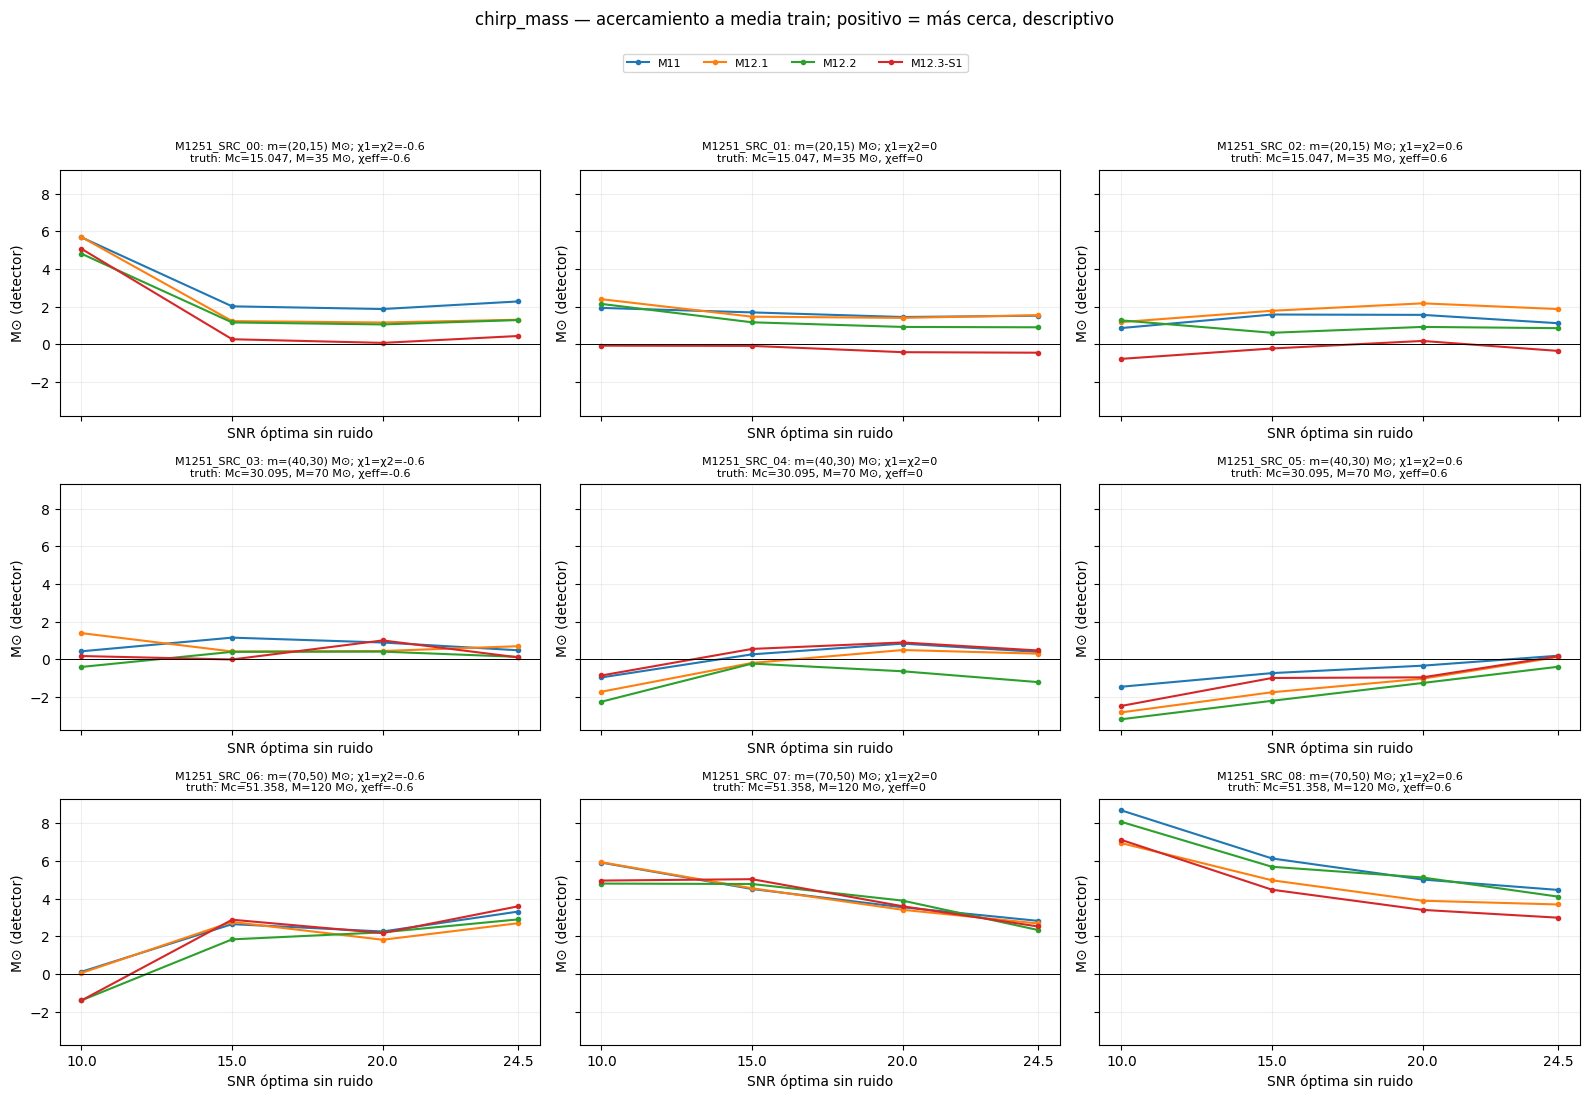

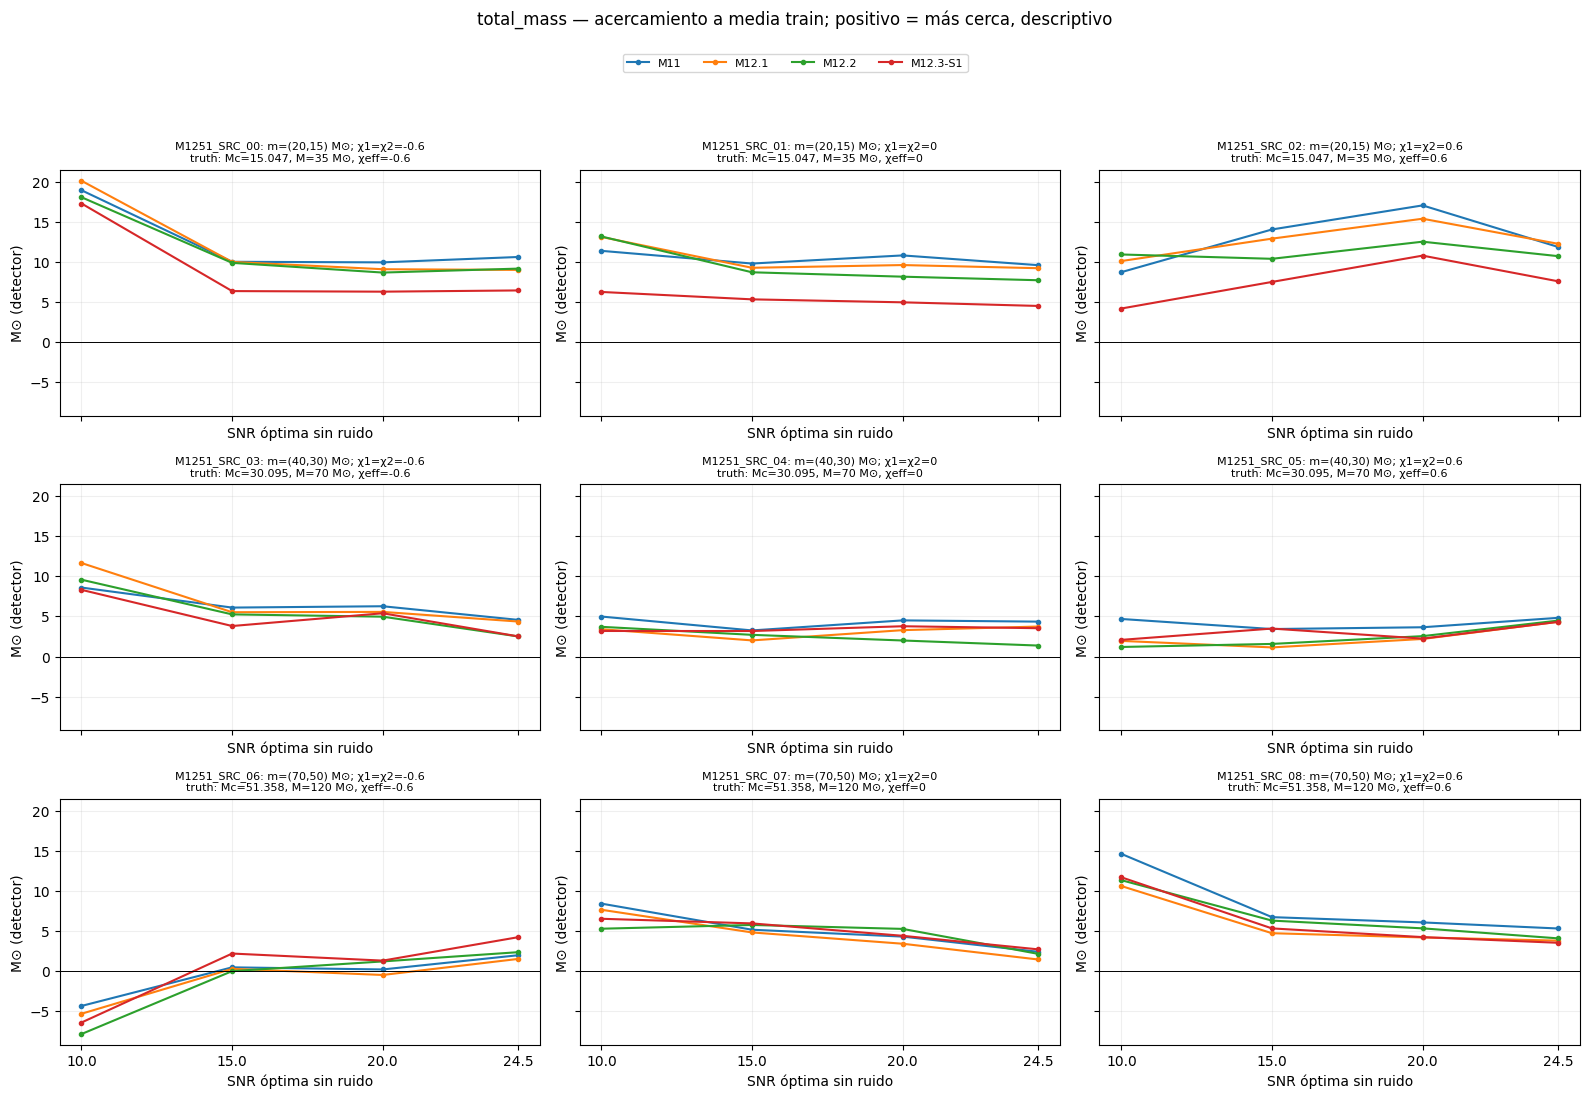

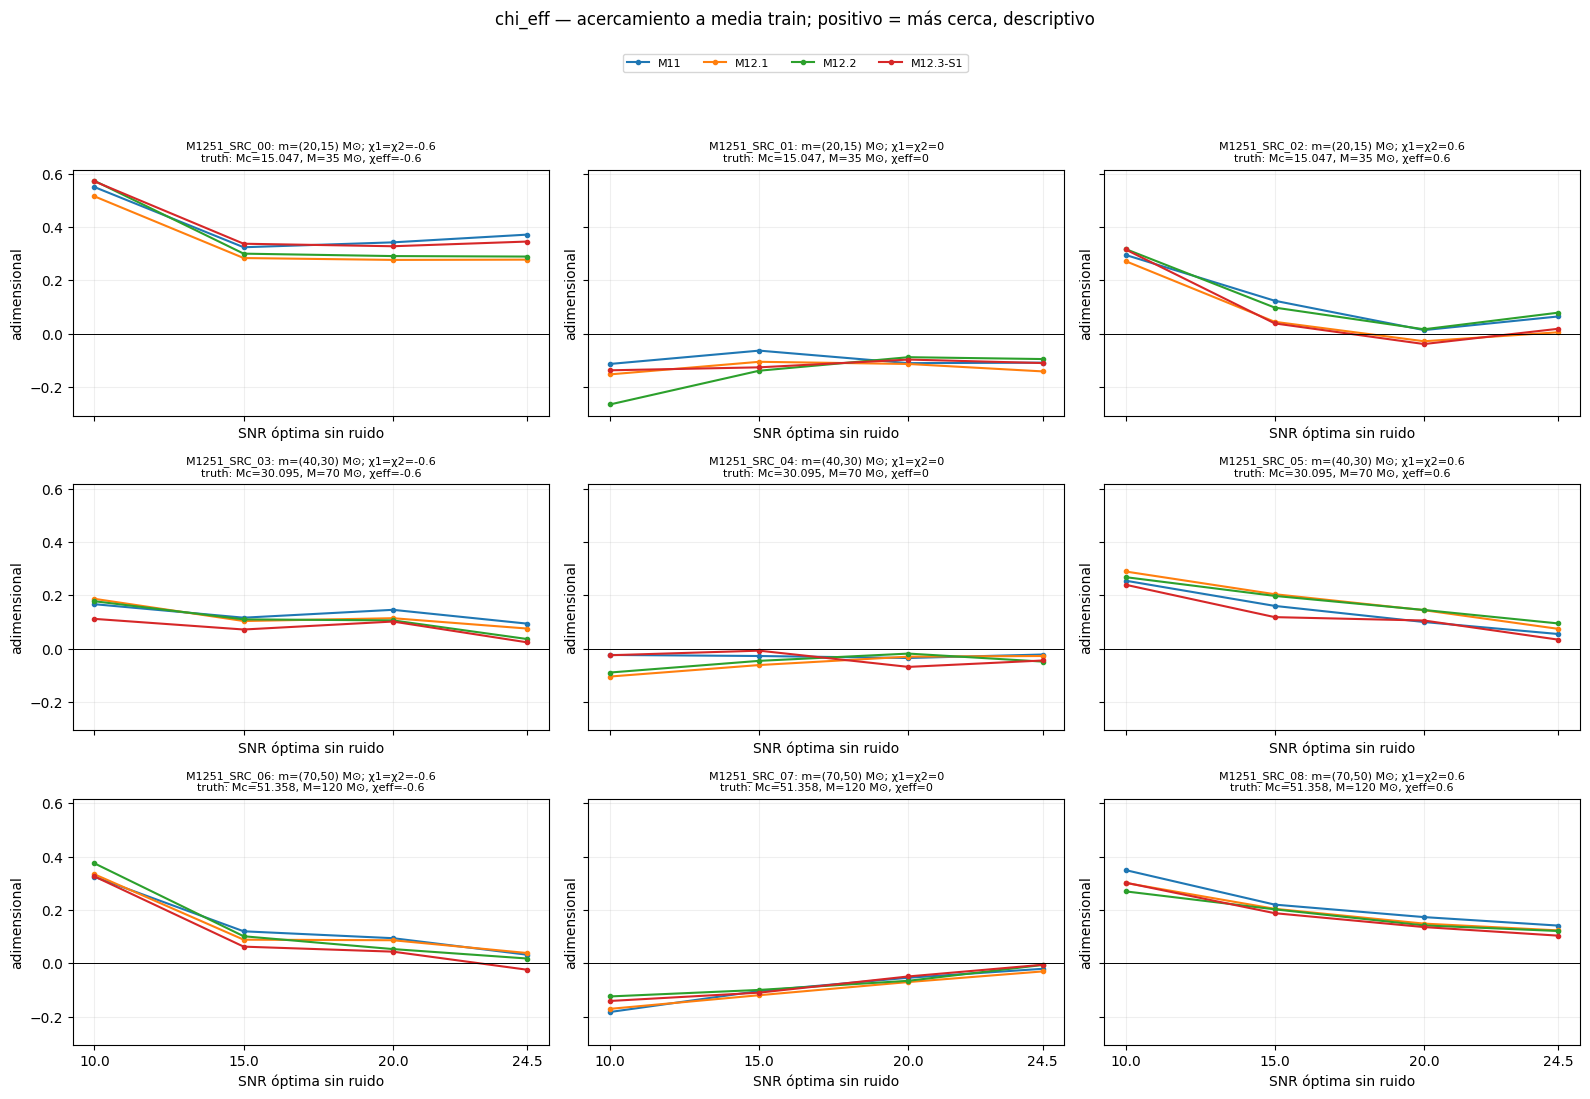

In [10]:
contraction = exhaustive.copy()
contraction["G1_train_mean"] = contraction.label.map(dict(zip(LABEL_ORDER, train_means)))
contraction["G1_train_std"] = contraction.label.map(dict(zip(LABEL_ORDER, train_stds)))
d = contraction.G1_train_mean - contraction.truth
contraction["near_train_mean"] = abs(d) <= .01*contraction.G1_train_std
contraction["bias_points_toward_mean"] = (contraction.bias*d > 0) & ~contraction.near_train_mean
contraction["distance_to_train_mean_reduction"] = abs(d) - abs(contraction.mean_prediction-contraction.G1_train_mean)
contraction["crossed_train_mean"] = ((contraction.truth-contraction.G1_train_mean) *
                                     (contraction.mean_prediction-contraction.G1_train_mean) < 0)
contraction["contraction_ratio"] = contraction.bias / d.where(~contraction.near_train_mean)
a = contraction.bias_ci_low / d.where(~contraction.near_train_mean)
b = contraction.bias_ci_high / d.where(~contraction.near_train_mean)
contraction["contraction_ratio_ci_low"] = np.minimum(a,b)
contraction["contraction_ratio_ci_high"] = np.maximum(a,b)
with pd.option_context("display.max_rows", 432):
    display(contraction[["source_id", "target_snr", "model", "label", "truth", "G1_train_mean",
                         "mean_prediction", "near_train_mean", "bias_points_toward_mean",
                         "distance_to_train_mean_reduction", "crossed_train_mean", "contraction_ratio",
                         "contraction_ratio_ci_low", "contraction_ratio_ci_high"]])
for label in LABEL_ORDER:
    fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
    for ax, sid in zip(axes.flat, SOURCE_ORDER):
        for model in MODEL_ORDER:
            frame = contraction[(contraction.source_id == sid) & (contraction.label == label)
                                & (contraction.model == model)].sort_values("target_snr")
            ax.plot(frame.target_snr, frame.distance_to_train_mean_reduction, "o-",
                    color=COLORS[model], label=model, markersize=3)
        ax.axhline(0, color="black", linewidth=.7)
    finish_grid(fig, axes, f"{label} — acercamiento a media train; positivo = más cerca, descriptivo",
                axis_unit(label))

### Discusión científica

**A. Robustness to noise — Robustez al ruido.** Comparar `sample_variance` y `noise_std` en las 432 condiciones tabuladas, con sus IC. Baja dispersión indica estabilidad del estimador ante estos ruidos y este entorno; debe leerse junto a sesgo y RMSE. No implica posterior estrecha. El bootstrap de 16 realizaciones es exploratorio: no caracteriza de forma fiable sucesos raros ni errores extremos.

**B. Residual systematic bias — Sesgo sistemático residual.** `endpoints` muestra el sesgo a SNR 24,5 y su incertidumbre de repetición, incluso cuando disminuye la varianza. “Persistente” significa presente al máximo SNR ensayado, no un límite de alta SNR ni un sesgo demostrado en toda la población. Un IC puntual que no cruza cero puede motivar seguimiento; con 108 comparaciones no equivale a evidencia simultánea controlada. Sesgo persistente no prueba capacidad arquitectónica insuficiente: prior, objetivo de entrenamiento, optimización, observable y nuisance parameters pueden contribuir.

**C. SNR dependence — Dependencia con SNR.** Las figuras incluyen los cuatro niveles para todas las fuentes. Los cambios alto−bajo se muestran sin imponer monotonía; una disminución de varianza puede coexistir con sesgo estable o creciente. La distancia cambia para fijar SNR óptima, mientras PSD y geometría permanecen fijas dentro de cada fuente. No extrapolar fuera de 10–24,5 ni tratar las dos SNR como ruidos emparejados.

**D. Differences between M11, M12.1, M12.2 and M12.3-S1.** `paired_full` contiene los seis pares de checkpoints con convención a−b y bootstrap emparejado por ruido. Diferencia negativa de RMSE favorece a “a” solo en esa condición; el signo de diferencia de sesgo firmado no ordena calidad por sí solo. M11 usa MSE ordinaria, M12.1 ponderación global, M12.2 ponderación marginal y M12.3-S1 muestreo balanceado: inducen distintos objetivos efectivos. Ninguna comparación de estos cuatro endpoints de una semilla demuestra reproducibilidad entre entrenamientos. No seleccionar nuevas variantes con este piloto.

**E. What repeated-noise analysis CAN establish.** Estima, para cada configuración fija y entorno documentado, la media del predictor sobre ruido, su sesgo respecto a la verdad, su varianza de muestreo, MSE y contrastes emparejados entre estimadores. Separa algebraicamente componentes del error empírico y describe su evolución dentro del rango de SNR ensayado. La tabla exhaustiva conserva los casos desfavorables y evita elegir ejemplos ilustrativos.

**F. What it CANNOT establish about the irreducible information limit.** Para una distribución conjunta fija de (X,Y), el mismo observable X, el mismo prior y segundos momentos finitos,

$$\mathbb E[(Y-f(X))^2]=\mathbb E[\operatorname{Var}(Y\mid X)]+\mathbb E[(\mathbb E[Y\mid X]-f(X))^2].$$

La identidad es por etiqueta (o se suma para error euclídeo). El primer término es riesgo Bayes bajo **esa distribución y ese observable**; el segundo es exceso de riesgo respecto a su media condicional. No se obtiene ninguno de ellos automáticamente repitiendo ruido en nueve verdades fijas. Aquí se estima otra descomposición:

$$\mathbb E_n[(f(X(\vartheta,n))-y(\vartheta))^2]=b_f(\vartheta)^2+\operatorname{Var}_n(f(X(\vartheta,n))),$$

cuya versión empírica exacta es $\widehat{MSE}=\widehat b^2+(R-1)s^2/R$. El ruido se promedia a parámetros físicos/extrínsecos y PSD fijos; no se integra la distribución posterior de parámetros dado un dato. Estabilidad no equivale a incertidumbre posterior pequeña; sesgo residual no identifica arquitectura deficiente, irreducibilidad ni Bayes-optimalidad.

**G. Requirements for the upcoming information-reference experiment.** Predefinir el observable (X normalizado frente a strain bruto), la información auxiliar disponible a cada método, el prior y la marginalización de nuisance parameters. Reproducir la distribución G1 inducida por SNR/distancia, colocación, fase fija, geometría, PSD y procesamiento; mantener las fuentes, realizaciones y checkpoints identificados por hashes. Una referencia bayesiana sobre strain bruto que recibe amplitud, contexto, PSD exacta o extrínsecos no suministrados a la CNN tiene más información: no es una comparación directa justa de eficiencia del estimador. Debe etiquetarse como referencia física condicionada diferente, o construir una referencia sobre el mismo X y prior. Verificar convergencia y precisión Monte Carlo de esa referencia, estudiar después más realizaciones/entornos y distinguir incertidumbre posterior, incertidumbre de entrenamiento y error de muestreo. No hay aquí autorización implícita para ejecutar ese experimento.

La lectura numérica de A–D debe apoyarse en las tablas calculadas, sin convertir esta discusión en conclusiones empíricas antes de ejecutar las nuevas celdas.

### Exportación opcional de tablas completas (solo CSV/JSON)

La celda siguiente no escribe por defecto. Si se activa, crea un directorio externo **nuevo** y exporta las 432 filas de métricas, 108 contrastes SNR, 648 contrastes de checkpoints y 432 diagnósticos de contracción. Nunca sobrescribe análisis previo. Las fracciones indefinidas y ratios omitidos se guardan vacíos en CSV. `analysis_provenance.json` registra fuentes, hashes, unidades, bootstrap y limitaciones; los resultados siguen condicionados a esta cuadrícula fija.

In [11]:
EXPORT_EXHAUSTIVE_TABLES = False
EXHAUSTIVE_OUTPUT_DIR = STUDY_DIR / "analysis_all_sources_v1"
if EXPORT_EXHAUSTIVE_TABLES:
    out = contracts.output_directory(ANALYSIS_DATA_ROOT, Path(EXHAUSTIVE_OUTPUT_DIR))
    tables = {"all_conditions.csv": exhaustive, "snr_24p5_minus_10.csv": endpoints,
              "all_paired_checkpoints.csv": paired_full, "train_mean_contraction.csv": contraction}
    for name, table in tables.items():
        table.to_csv(out / name, index=False, mode="x")
    contracts.write_json(out / "analysis_provenance.json", dict(
        schema="M12.5.1-all-sources-analysis-v1", complete=True,
        notebook=contracts.record(ANALYSIS_ROOT / "notebooks/m12/M12_5_1_repeated_noise_pilot.ipynb", True),
        analysis_utility=contracts.record(ANALYSIS_ROOT / "scripts/m12/analyze_m12_5_1.py", True),
        metric_contract=contracts.record(ANALYSIS_ROOT / "scripts/m12/m12_5_common.py", True),
        predictions=contracts.record(EXHAUSTIVE_INFERENCE_DIR / "predictions.csv", True),
        inference=contracts.record(EXHAUSTIVE_INFERENCE_DIR / "inference.json", True),
        generation=contracts.record(PILOT_METADATA_DIR / "generation.json", True),
        conditions=contracts.record(PILOT_METADATA_DIR / "conditions.csv", True),
        observations=contracts.record(PILOT_METADATA_DIR / "observations.csv", True),
        numpy_version=np.__version__, pandas_version=pd.__version__,
        bootstrap_replicates=BOOTSTRAP_REPLICATES, bootstrap_seed_policy="SeedSequence([125002, condition_id, label_index])",
        resampling="within fixed condition; paired models; independent SNR conditions",
        interval="pointwise exploratory 95% percentile; transformed bounds for sd/RMSE/absolute bias",
        absolute_bias_change="marginal-bound envelope, not a nominal joint 95% CI",
        units={"mass": "Msun_detector_frame", "spin": "dimensionless", "variance_MSE": "squared label units"},
        finite_R_identity="MSE=bias^2+(R-1)/R*unbiased_sample_variance",
        contraction_ratio_exclusion="abs(truth-train_mean)<=0.01*train_std",
        limitations="R=16; fixed designed sources and one environment; no population/posterior/training-seed inference; no multiplicity correction",
        outputs={name: contracts.record(out / name, True) for name in tables}))
    print("Written:", out)
else:
    print("No exports written; set EXPORT_EXHAUSTIVE_TABLES=True only for a new external destination.")

No exports written; set EXPORT_EXHAUSTIVE_TABLES=True only for a new external destination.


## Scientific conclusions — M12.5.1: Controlled repeated-noise pilot

### 1. Experimental scope and reproducibility

M12.5.1 investigated the response of the frozen M11, M12.1, M12.2 and M12.3-S1 CNN estimators to independent noise realizations at fixed BBH physical configurations.

The experiment comprised nine BBH systems, four target network SNR levels (10, 15, 20 and 24.5), and 16 independent noise realizations per source–SNR condition, producing **576 distinct observations and 2,304 model predictions**.

The generation procedure reproduced the frozen G1 processing contract, including the waveform approximant, detector projection, PSD-conditioned Gaussian noise, temporal context, filtering, cropping and per-detector z-score normalization.

The G1 reproduction gate had previously achieved bitwise equality for three reference train observations, including a repaired source.

The four checkpoints received identical observation tensors within each condition. Checkpoint identities, label scalers, source parameters, SNR metadata, observation identities and noise seeds were verified.

The analysis produced 432 source–SNR–model–label summaries and 108 comparisons between the lowest and highest SNR levels.

The empirical error decomposition was numerically verified:

$$
\widehat{\mathrm{MSE}}
=
\widehat{\mathrm{Bias}}^2
+
\frac{R-1}{R}s^2,
$$

with a maximum numerical residual of approximately $2.84\times10^{-13}$.

The experiment therefore provides a reproducible characterization of conditional estimator performance under the selected physical and environmental conditions.

### 2. Strong dependence of estimator performance on SNR

Increasing the network SNR generally reduced the dispersion of predictions across noise realizations.

For almost every combination of source, checkpoint and target, the sample variance decreased between SNR 10 and 24.5.

The improvement was also reflected in conditional RMSE.

The following table reports the arithmetic mean of the nine source-specific conditional RMSE values, not the RMSE of the full G1 population:

| Target | Model | Mean RMSE, SNR 10 | Mean RMSE, SNR 24.5 |
|---|---|---:|---:|
| Chirp mass | M11 | 5.336 | 2.718 |
| Chirp mass | M12.1 | 5.944 | 2.387 |
| Chirp mass | M12.2 | 5.826 | 2.330 |
| Chirp mass | M12.3-S1 | 5.506 | 2.133 |
| Total mass | M11 | 13.798 | 7.691 |
| Total mass | M12.1 | 14.313 | 6.874 |
| Total mass | M12.2 | 13.905 | 6.645 |
| Total mass | M12.3-S1 | 13.142 | 5.895 |
| Effective spin | M11 | 0.351 | 0.149 |
| Effective spin | M12.1 | 0.359 | 0.128 |
| Effective spin | M12.2 | 0.364 | 0.137 |
| Effective spin | M12.3-S1 | 0.355 | 0.126 |

Mass errors are expressed in solar masses; effective-spin errors are dimensionless.

These results demonstrate that the learned estimators are sensitive to changes in observational quality and generally become more accurate and stable as the SNR increases.

Nevertheless, the SNR dependence is not uniformly monotonic for every source and metric. A reduction in noise variance does not necessarily imply a corresponding reduction in systematic bias.

### 3. Persistent conditional bias and regression contraction

A central finding is that improvements in noise stability do not eliminate systematic prediction errors.

For M11, the average absolute conditional bias across the nine sources changed as follows:

| Target | SNR 10 | SNR 24.5 |
|---|---:|---:|
| Chirp mass | 2.897 | 1.841 |
| Total mass | 9.414 | 6.172 |
| Effective spin | 0.251 | 0.101 |

Although absolute bias generally decreased, non-negligible residual biases remained at SNR 24.5.

For the three systems with total mass $35\,M_\odot$, M11 retained positive total-mass biases of approximately $+10.6$, $+9.6$ and $+11.8\,M_\odot$.

The highest-mass systems showed negative total-mass biases, consistent with the previously identified tendency to overestimate low masses and underestimate high masses.

The analysis of contraction toward the G1 training means provides additional evidence.

At SNR 24.5, the mean prediction was displaced toward the G1 training mean in:

- 32 of 36 model–source combinations for chirp mass.
- 36 of 36 combinations for total mass.
- 23 of 36 combinations for effective spin.

These frequencies describe the direction of the conditional bias relative to the training mean. They do not demonstrate that all predictions move closer to the training mean by the same amount, nor that the contraction is Bayes-optimal.

The systematic nature of some residual errors indicates that noise-induced prediction variance alone is insufficient to explain the observed conditional MSE.

However, persistent bias does **not** establish that the CNN architecture is deficient. It may also arise from the conditional target distribution, learned training prior, intrinsic–extrinsic parameter degeneracies, optimization limitations or information loss in preprocessing.

### 4. Bias–variance decomposition

For a fixed physical configuration $\vartheta$, the noise-averaged error of a deterministic estimator can be decomposed as


$$
\mathrm{MSE}_f(\vartheta)
=
b_f(\vartheta)^2
+
\mathrm{Var}_n[f(X(\vartheta,n))].
$$

The empirical analysis uses the exact finite-sample version of this identity.

The results show that bias and noise variance can contribute substantially different fractions of conditional MSE depending on the source, target, SNR and checkpoint.

In particular, the reduction of noise variance at high SNR can expose a residual bias-dominated error.

This distinction is essential: an estimator that produces nearly identical predictions for repeated noisy observations is not necessarily accurate.

The analysis therefore establishes that **prediction stability cannot be used as a substitute for parameter-estimation accuracy**.

### 5. Comparison between frozen checkpoints

The four checkpoints exhibit different conditional bias–variance trade-offs.

At SNR 24.5, M12.3-S1 achieved the smallest mean source-specific conditional RMSE among the four models for all three targets in this particular nine-source grid.

For example, its mean RMSE was approximately:

- $2.133\,M_\odot$ for chirp mass.
- $5.895\,M_\odot$ for total mass.
- $0.126$ for effective spin.

These findings indicate that the M12 interventions can modify conditional estimator performance, including systematic error and noise sensitivity.

However, the nine physical sources were deliberately selected and do not represent the G1 validation distribution.

The pilot therefore does not overturn the earlier validation results, where some M12 interventions improved peripheral mass estimation at the expense of global performance or effective-spin accuracy.

The paired comparisons exploit identical noise realizations across models, reducing noise-induced variability in checkpoint contrasts. Nevertheless, they characterize these particular frozen checkpoints and cannot quantify variation across independent training seeds.

**No checkpoint selection or architectural decision should be based solely on this pilot.**

### 6. Scientific interpretation: observational information versus estimator limitations

The purpose of M12.5 is to distinguish two mechanisms:

**H1 — Information limitation.** The observed data do not sufficiently constrain the physical parameters because of noise, degeneracies or information discarded by preprocessing.

**H2 — Estimator limitation.** Information about the physical parameters is present in the observed data, but the CNN does not extract or use it optimally.

The present experiment establishes that the errors of our CNN estimators contain both noise-sensitive and persistent systematic components.

However, it does not quantify how much of the systematic component is avoidable.

Under a fixed joint distribution $p(X,Y)$, a fixed observable $X$ and squared-error loss,


$$
\boxed{
\mathbb E[(Y-f(X))^2]
=
\underbrace{\mathbb E[\mathrm{Var}(Y\mid X)]}_{R^*}
+
\underbrace{\mathbb E[(f(X)-\mathbb E[Y\mid X])^2]}_{\text{Excess estimator risk}}.
}
$$

The first term represents the irreducible Bayes risk under the specified observation model and prior. The second measures the error beyond the optimal conditional-mean estimator.

Crucially, repeated noise realizations at fixed physical parameters do not identify either term separately.

The pilot therefore cannot determine whether the remaining CNN bias reflects insufficient physical information or a suboptimal estimator.

A stable but biased CNN prediction may be compatible with a broad posterior distribution. Conversely, it may indicate information that another estimator could exploit more effectively.

### 7. Information loss introduced by preprocessing

A further distinction is required between the information contained in physical detector strain and the information available in the CNN input tensor.

The G1 preprocessing applies whitening, frequency filtering, temporal cropping and independent per-detector z-score normalization.

Consequently, the CNN does not receive the original untransformed strain.

In particular, per-detector normalization strongly modifies information related to absolute amplitude and relative detector scales, although waveform morphology and signal prominence relative to noise remain partially accessible.

Thus, the following quantities must be distinguished:

1. Information recoverable from the original detector strain, together with explicitly available PSD and auxiliary information.
2. Information recoverable from the normalized G1 tensor $X$.
3. Information actually extracted by the frozen CNN estimator.

These distinctions are essential before attributing an apparent precision limit to gravitational-wave physics or to neural-network architecture.

### 8. Statistical and experimental limitations

The present pilot is conditioned on nine physical configurations, one selected PSD environment and fixed extrinsic parameters and placement per source.

It does not marginalize over the complete G1 population of intrinsic parameters, extrinsic configurations, PSD environments and temporal placements.

Each condition contains only 16 independent noise realizations. Consequently, uncertainty intervals remain sensitive to Monte Carlo variability and cannot reliably characterize rare errors or distribution tails.

The multiple source-specific and checkpoint-specific comparisons should be interpreted as exploratory rather than as a family-wise controlled statistical discovery.

Furthermore, the SNR variation is implemented through distance rescaling, according to the G1 optimal-network-SNR definition. The results should not be extrapolated to alternative SNR definitions or outside the studied range.

Finally, all four checkpoints are deterministic point estimators. Their variability across noise realizations is not equivalent to posterior uncertainty, epistemic uncertainty or